# Project : Act 8. DEMANDA-IA · Monitorización proactiva, alertas y respuesta automatizada JGOL

###   Name: José Gerardo Ortiz Leñero
    Matricula: AL07182099
    Date: Noviembre 15 de 2026
    Universidad TecMilenio

# DEMANDA-IA · Actividad 8
Simula 30 días de operación (1 al 30 de octubre de 2026) del pronóstico de demanda DEMANDA-IA (20 sucursales × 60 SKU = 1,200 series) y, en orden:

1. Genera un histórico sintético de ventas por SKU y sucursal.
2. Entrena y registra cuatro versiones del modelo en **MLflow** (Tracking + Model Registry, alias `champion` / `previous` / `challenger`).
3. Instrumenta el servicio con **métricas**, **logs JSON** y **trazas OpenTelemetry**.
4. Define SLO, presupuestos de error y reglas de alerta (YAML) y las evalúa con un motor de alertas por *burn rate*.
5. Inyecta tres incidentes (saturación de la API, modelo v3 defectuoso y *data drift* por frente frío) y ejecuta los runbooks RB-01 a RB-03 de forma automatizada.
6. Exporta tableros, reportes, configuración e informes de incidente como artefactos de MLflow.

**Entorno.** Se ejecutó en un entorno local (Windows 11, Visual Studio Code, Python 3.13 en entorno virtual, MLflow 3 con backend SQLite). También corre en Google Colab: la primera celda instala lo que falte. La simulación usa semilla fija y el reloj simulado en UTC, así que los resultados no dependen del equipo ni de la zona horaria.

**Cómo ejecutarlo**

* *Colab:* Entorno de ejecución → Ejecutar todas. La sección 13 abre la interfaz de MLflow.
* *Local:* con el entorno virtual activado y `pip install -r requirements.txt`, abrir el notebook en Jupyter o VS Code y ejecutar todas las celdas. Si ya existe la carpeta `demanda_ia_obs` de una corrida previa, renombrarla antes para no duplicar versiones en el Model Registry. Al final, la sección 13 imprime el comando para levantar MLflow.

**Resultados esperados:** 4 notificaciones contra 193 con reglas de umbral fijo; MTTD de 10, 1,740 y 138.8 min; 26 de 29 días con WMAPE ≤ 32 % (presupuesto de calidad en 0 %); disponibilidad de la API de 99.84 %.

## 1. Configuración general

In [ ]:
# =============================================================================
# Celda 0.- Dependencias.
# =============================================================================
# (pip install -r requirements.txt) y esta celda no cambia nada.
%pip install -q "mlflow>=3.0" opentelemetry-sdk pyyaml

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# =============================================================================
# Celda 1.- Importación de Librerias.
# =============================================================================
import sys
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")
    sys.stderr.reconfigure(encoding="utf-8", errors="replace")

try:
    from IPython.display import display
except ImportError:
    display = print
import json, math, logging, warnings, uuid
from pathlib import Path
from datetime import datetime, timedelta, timezone
from collections import deque, defaultdict


import numpy as np
import pandas as pd
import yaml
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

import mlflow
from mlflow.tracking import MlflowClient
from mlflow.entities import Metric

from opentelemetry import trace
from opentelemetry.sdk.trace import TracerProvider
from opentelemetry.sdk.resources import Resource
from opentelemetry.sdk.trace.export import SimpleSpanProcessor
from opentelemetry.sdk.trace.export.in_memory_span_exporter import InMemorySpanExporter
from opentelemetry.trace import Status, StatusCode

warnings.filterwarnings("ignore")
logging.getLogger("mlflow").setLevel(logging.ERROR)

SEED = 42
rng = np.random.default_rng(SEED)

BASE = Path("demanda_ia_obs").resolve()
for sub in ["config", "logs", "traces", "reports", "figs", "incidents", "mlartifacts"]:
    (BASE / sub).mkdir(parents=True, exist_ok=True)

mlflow.set_tracking_uri(f"sqlite:///{BASE/'mlflow.db'}")
client = MlflowClient()
REG_MODEL = "demanda-ia-forecaster"

def get_exp(name):
    exp = mlflow.get_experiment_by_name(name)
    if exp is None:
        return mlflow.create_experiment(name, artifact_location=(BASE / "mlartifacts" / name).as_uri())
    return exp.experiment_id

EXP_TRAIN = get_exp("DEMANDA-IA/entrenamiento")
EXP_MON = get_exp("DEMANDA-IA/monitoreo-produccion")

SIM_START = datetime(2026, 10, 1)
SIM_DAYS = 30
TICK = timedelta(minutes=5)
print("Tracking URI:", mlflow.get_tracking_uri())

Tracking URI: sqlite:///C:\Users\JoseGerardoOrtiz\Act8\demanda_ia_obs\mlflow.db


### Vínculo con el caso de negocio (Actividad 3)

Los umbrales del notebook salen del modelo financiero de la Actividad 3 (`Act_3__ROI_DEMANDA-IA_FOS_JGOL.xlsx`). Tres de los beneficios tangibles dependen directamente de la exactitud del pronóstico: B01 (ventas recuperadas por faltantes), B02 (menor costo de mantener inventario) y B03 (menos merma por caducidad). En el Año 3, con adopción del 100 %, suman 15.78 millones de pesos. Repartidos en el año son unos 43 mil pesos diarios, y esa es la referencia que se usa aquí para poner precio a un día de pronóstico fuera de SLO.

El registro de riesgos de la Actividad 3 también aparece en la operación: R08 (deriva de la demanda) se vigila con el monitor de drift y el runbook RB-03; R10 (falla del batch o del ERP) con el SLO-BATCH y RB-04; R12 (exceso de alertas) con el control de ruido; R09 y R14 (dependencia de personas y documentación) con runbooks ejecutables y artefactos versionados en MLflow.

In [ ]:
# =============================================================================
# Celda 2.- Datos obtenidos de de los modelos generados para DEMANDA-IA.
# =============================================================================
ACT3 = {
    "sucursales": 140, "sku_activos": 8000, "ventas_anuales_mxn": 2_100_000_000,
    "beneficios_precision_anio3": {"B01_ventas_recuperadas": 5_659_500, "B02_costo_inventario": 5_616_000,
                                   "B03_merma_caducidad": 4_504_500},
    "nivel_servicio_actual": 0.91, "nivel_servicio_meta": 0.96,
    "roi_conservador": 0.5408, "roi_pesimista": 0.0049, "vpn_conservador_mxn": 10_632_745, "payback_meses_golive": 18.6,
    "riesgos_emv_anual": {"R08_deriva": (1_260_000, 210_000), "R10_batch_erp": (325_000, 86_667),
                          "R11_nube": (100_000, 66_667), "R12_exceso_alertas": (75_000, 30_000)},
    "presupuesto_monitoreo_C17_anual": 150_000,
}
BENEFICIO_PRECISION_ANUAL = sum(ACT3["beneficios_precision_anio3"].values())
COSTO_DIA_FUERA_SLO = BENEFICIO_PRECISION_ANUAL / 365
print(f"Beneficio anual que depende de la exactitud (B01+B02+B03, Año 3): ${BENEFICIO_PRECISION_ANUAL:,.0f} MXN")
print(f"Valor en riesgo por cada día de pronóstico fuera de SLO:         ${COSTO_DIA_FUERA_SLO:,.0f} MXN")
print(f"Presupuesto de error de calidad (3 días/mes) en dinero:            ${3 * COSTO_DIA_FUERA_SLO:,.0f} MXN/mes")
print(f"EMV residual anual de R08 aceptado en la Actividad 3:              ${ACT3['riesgos_emv_anual']['R08_deriva'][1]:,.0f} MXN"
      f" (≈ {ACT3['riesgos_emv_anual']['R08_deriva'][1] / COSTO_DIA_FUERA_SLO:.1f} días/año)")

Beneficio anual que depende de la exactitud (B01+B02+B03, Año 3): $15,780,000 MXN
Valor en riesgo por cada día de pronóstico fuera de SLO:         $43,233 MXN
Presupuesto de error de calidad (3 días/mes) en dinero:            $129,699 MXN/mes
EMV residual anual de R08 aceptado en la Actividad 3:              $210,000 MXN (≈ 4.9 días/año)


## 2. Datos sintéticos de demanda

Cada serie es la venta diaria de un SKU en una sucursal. La demanda depende del tamaño de la sucursal, del día de la semana, de las promociones (que el área comercial conoce con anticipación) y, para la categoría respiratoria, de la temperatura.

Dos detalles que importan para los incidentes de octubre:

* Cada sucursal tiene su propia temperatura (las 140 tiendas están en zonas distintas del occidente). A partir del **22 de octubre** entra un frente frío con temperaturas que el modelo casi no vio (media regional de ~10.5 °C cuando el mínimo histórico ronda los 12-14 °C) y arranca una campaña de temporada en productos respiratorios. Eso es el *data drift* del incidente 3.
* El pronóstico tiene horizonte de 7 días, así que todas las variables de rezago usan como mínimo `lag 7`.

In [ ]:
# =============================================================================
# Celda 3.- Generación de datos sinteticos para entrenar modelo.
# =============================================================================
N_SUC, N_SKU = 20, 60
CATS = ["respiratorio", "analgesicos", "cronicos", "cuidado_personal", "dermocosmetica"]
fechas = pd.date_range("2025-07-01", "2026-10-30", freq="D")
T = len(fechas)

sku_cat = rng.choice(len(CATS), N_SKU, p=[.25, .2, .25, .15, .15])
sku_base = rng.lognormal(2.6, 0.6, N_SKU)
suc_size = rng.uniform(0.6, 1.8, N_SUC)
dow_f = np.array([1.05, .95, .95, 1.0, 1.1, 1.2, .8])

doy = fechas.dayofyear.values
temp = 21 + 4.5 * np.sin(2 * np.pi * (doy - 105) / 365) + rng.normal(0, 1.2, T)
frio = np.asarray(fechas >= "2026-10-22")
temp[frio] = rng.normal(10.5, 1.0, frio.sum())
suc_temp_off = rng.uniform(-2, 2, N_SUC)                       # sucursales en distintas zonas del occidente
temp_suc = temp[:, None] + suc_temp_off[None, :] + rng.normal(0, 0.6, (T, N_SUC))   # (T, SUC)

weeks = (np.arange(T) + fechas[0].dayofweek) // 7
promo_w = rng.random((weeks.max() + 1, N_SKU)) < 0.18
wk22 = weeks[np.argmax(frio)]
campana = rng.random((weeks.max() + 1, N_SKU)) < 0.6
promo_w[wk22:] |= campana[wk22:] & (sku_cat[None, :] == 0)
promo = promo_w[weeks]                                   # (T, SKU)
promo_lift = rng.uniform(1.8, 2.6, N_SKU)

t = temp_suc[:, :, None]                                       # (T, SUC, 1)
cat3 = sku_cat[None, None, :]
temp_f = np.ones((T, N_SUC, N_SKU))
temp_f = np.where(cat3 == 0, 1 + 0.06*np.clip(22-t, 0, None) + 0.10*np.clip(14-t, 0, None)**1.5, temp_f)
temp_f = np.where(cat3 == 1, 1 + 0.02*np.clip(22-t, 0, None), temp_f)

lam = (suc_size[None, :, None] * sku_base[None, None, :]
       * dow_f[fechas.dayofweek.values][:, None, None]
       * np.where(promo, promo_lift[None, :], 1)[:, None, :]
       * temp_f
       * (1 + 0.0002 * np.arange(T))[:, None, None])
Y = rng.poisson(lam * rng.gamma(30, 1/30, lam.shape)).astype(float)   # (T, SUC, SKU)

def shift(a, k):
    out = np.full_like(a, np.nan); out[k:] = a[:-k]; return out

def roll_mean(a, w, k):
    c = np.concatenate([np.zeros((1,) + a.shape[1:]), np.cumsum(np.nan_to_num(a), 0)])
    out = np.full_like(a, np.nan)
    for i in range(w + k - 1, len(a)):
        out[i] = (c[i-k+1] - c[i-k+1-w]) / w
    return out

FEAT = {
    "lag7": shift(Y, 7), "lag14": shift(Y, 14), "lag28": shift(Y, 28),
    "rm7": roll_mean(Y, 7, 7), "rm28": roll_mean(Y, 28, 7),
    "dow_mean4": (shift(Y, 7) + shift(Y, 14) + shift(Y, 21) + shift(Y, 28)) / 4,
    "promo": np.broadcast_to(promo[:, None, :], Y.shape).astype(float),
    "temp": np.broadcast_to(temp_suc[:, :, None], Y.shape),
    "dow": np.broadcast_to(fechas.dayofweek.values[:, None, None], Y.shape).astype(float),
    "cat": np.broadcast_to(sku_cat[None, None, :], Y.shape).astype(float),
}
FEATURES = list(FEAT)
KEY_FEATURES = ["lag7", "rm28", "promo", "dow_mean4"]      # PSI; la temperatura se vigila aparte (ver sección 7)

def day_idx(d):
    return int(np.where(fechas == pd.Timestamp(d).normalize())[0][0])

def rows(i0, i1, suc=None):
    """Matriz de features y vector objetivo para los días [i0, i1)."""
    sl = slice(None) if suc is None else suc
    X = np.stack([FEAT[f][i0:i1][:, sl].reshape(-1) for f in FEATURES], 1)
    y = Y[i0:i1][:, sl].reshape(-1)
    return X, y

def wmape(y, p): return float(np.abs(y - p).sum() / y.sum())
def bias(y, p): return float((p.sum() - y.sum()) / y.sum())

print(f"{T} días x {N_SUC} sucursales x {N_SKU} SKU = {Y.size:,} registros")
print(pd.Series(CATS)[sku_cat].value_counts().to_string())

487 días x 20 sucursales x 60 SKU = 584,400 registros
cuidado_personal    15
respiratorio        15
cronicos            14
analgesicos         10
dermocosmetica       6


## 3. Entrenamiento y registro de versiones en MLflow

Se registran cuatro versiones. Cada corrida guarda parámetros, métricas de validación, firma del modelo y etiquetas de linaje.

| Versión | Datos hasta | Situación |
|---|---|---|
| v1 | 30-jun-2026 | Primer modelo productivo, ya archivado |
| v2 | 30-sep-2026 | `champion` al inicio de octubre |
| v3 | 15-oct-2026 | Reentrenamiento semanal con un defecto en el pipeline: la columna `promo` llega en ceros por un *join* con llave equivocada. La compuerta de validación de entonces solo pedía WMAPE ≤ 38 %, así que pasó |
| v4 | 24-oct-2026 | Reentrenamiento disparado por el runbook de drift: ventana de 150 días, peso ×10 a los últimos 10 días, árboles más regularizados y compuertas relativas al champion |

In [ ]:
# =============================================================================
# Celda 4.- Entrenar el modelo 4 versiones demanda-ia-forecaster.
# =============================================================================
def holdout_metrics(model, end_i, bug=False, n_days=7):
    X_clean, y = rows(end_i - n_days + 1, end_i + 1)
    X = X_clean.copy()
    if bug:
        X[:, FEATURES.index("promo")] = 0
    p = model.predict(X)
    is_promo = X_clean[:, FEATURES.index("promo")] == 1
    is_resp = X_clean[:, FEATURES.index("cat")] == 0
    return {
        "wmape_holdout": wmape(y, p), "bias_holdout": bias(y, p),
        "wmape_promo_holdout": wmape(y[is_promo], p[is_promo]),
        "wmape_respiratorio_holdout": wmape(y[is_resp], p[is_resp]),
    }

def train_version(end_date, tag, bug=False, recent_weight=False, gate="absoluta_38", window_days=300, holdout_days=7,
                  model_params=None, weight=8.0):
    end_i = day_idx(end_date)
    i0 = max(35, end_i + 1 - window_days)
    X, y = rows(i0, end_i + 1 - holdout_days)       # los últimos días quedan como holdout
    if bug:
        X[:, FEATURES.index("promo")] = 0           # defecto simulado del pipeline de features
    sw = None
    if recent_weight:
        d = np.repeat(np.arange(i0, end_i + 1 - holdout_days), N_SUC * N_SKU)
        sw = np.where(d >= end_i - 9 - holdout_days, weight, 1.0)
    params = dict(loss="poisson", max_iter=300, learning_rate=0.08, max_leaf_nodes=63,
                  categorical_features=[FEATURES.index("dow"), FEATURES.index("cat")], random_state=0)
    params.update(model_params or {})
    m = HistGradientBoostingRegressor(**params).fit(X, y, sample_weight=sw)
    hm = holdout_metrics(m, end_i, bug=bug, n_days=holdout_days)
    # reentrena con todo, incluido el holdout, para el modelo que se publica
    Xf, yf = rows(i0, end_i + 1)
    if bug:
        Xf[:, FEATURES.index("promo")] = 0
    swf = None
    if recent_weight:
        d = np.repeat(np.arange(i0, end_i + 1), N_SUC * N_SKU)
        swf = np.where(d >= end_i - 9, weight, 1.0)
    m = HistGradientBoostingRegressor(**params).fit(Xf, yf, sample_weight=swf)

    with mlflow.start_run(experiment_id=EXP_TRAIN, run_name=f"train-{tag}") as run:
        mlflow.log_params({**{k: v for k, v in params.items() if k != "categorical_features"},
                           "datos_hasta": str(pd.Timestamp(end_date).date()), "ventana_dias": window_days,
                           "peso_reciente": weight if recent_weight else 1, "features": ",".join(FEATURES),
                           "compuerta_validacion": gate, "dias_holdout": holdout_days})
        mlflow.log_metrics(hm)
        mlflow.set_tags({"version_logica": tag, "proyecto": "DEMANDA-IA", "cliente": "Farmacias Occidente Salud",
                         "horizonte": "7 dias", "granularidad": "SKU x sucursal x dia"})
        info = mlflow.sklearn.log_model(m, name="model", registered_model_name=REG_MODEL, serialization_format="cloudpickle",
                                        input_example=pd.DataFrame(Xf[:3], columns=FEATURES))
    version = info.registered_model_version
    client.update_model_version(REG_MODEL, version, description=f"{tag}: datos hasta {pd.Timestamp(end_date).date()}")
    client.set_model_version_tag(REG_MODEL, version, "version_logica", tag)
    print(f"{tag} -> versión registrada {version} | " + " | ".join(f"{k}={v:.3f}" for k, v in hm.items()))
    return m, version, hm, run.info.run_id

MODELS, VERSIONS = {}, {}
for tag, end in [("v1", "2026-06-30"), ("v2", "2026-09-30")]:
    m, ver, hm, _ = train_version(end, tag)
    MODELS[tag], VERSIONS[tag] = m, ver

client.set_registered_model_alias(REG_MODEL, "champion", VERSIONS["v2"])
client.set_registered_model_alias(REG_MODEL, "previous", VERSIONS["v1"])
client.set_model_version_tag(REG_MODEL, VERSIONS["v1"], "estado", "archivado")
REF_MODEL_TAG = "v2"

Successfully registered model 'demanda-ia-forecaster'.
Created version '1' of model 'demanda-ia-forecaster'.


v1 -> versión registrada 1 | wmape_holdout=0.248 | bias_holdout=-0.026 | wmape_promo_holdout=0.215 | wmape_respiratorio_holdout=0.241


v2 -> versión registrada 2 | wmape_holdout=0.261 | bias_holdout=0.013 | wmape_promo_holdout=0.235 | wmape_respiratorio_holdout=0.276


Registered model 'demanda-ia-forecaster' already exists. Creating a new version of this model...
Created version '2' of model 'demanda-ia-forecaster'.


## 4. Instrumentación: logs estructurados y trazas

**Logs.** Cada evento se escribe como una línea JSON con campos fijos (`ts`, `level`, `service`, `event`, `trace_id`, `model_version`, etc.). Así se pueden consultar en Kibana o Loki sin parsear texto libre.

**Trazas.** Se usa el SDK de OpenTelemetry. Como la simulación corre más rápido que el reloj real, cada *span* recibe sus tiempos de inicio y fin de forma explícita. Se aplica muestreo por cola (*tail sampling*): se guardan todas las solicitudes con error o lentas y una de cada hora en condiciones normales.

In [ ]:
# =============================================================================
# Celda 5.- Generación y seteo de Logs y trazas.
# =============================================================================
class JsonFormatter(logging.Formatter):
    def format(self, r):
        base = {"ts": getattr(r, "sim_ts", datetime.utcnow()).isoformat(timespec="seconds"),
                "level": r.levelname, "service": getattr(r, "service", "demanda-ia"),
                "event": getattr(r, "event", "log"), "msg": r.getMessage()}
        base.update(getattr(r, "fields", {}))
        return json.dumps(base, ensure_ascii=False)

LOG_PATH = BASE / "logs" / "demanda_ia.jsonl"
LOG_PATH.write_text("")
logger = logging.getLogger("demanda-ia")
logger.handlers.clear(); logger.setLevel(logging.INFO); logger.propagate = False
_h = logging.FileHandler(LOG_PATH, encoding="utf-8"); _h.setFormatter(JsonFormatter()); logger.addHandler(_h)

def log(ts, level, service, event, msg, **fields):
    logger.log(getattr(logging, level), msg,
               extra={"sim_ts": ts, "service": service, "event": event, "fields": fields})

span_exporter = InMemorySpanExporter()
provider = TracerProvider(resource=Resource.create({"service.name": "demanda-ia", "deployment.environment": "produccion"}))
provider.add_span_processor(SimpleSpanProcessor(span_exporter))
tracer = provider.get_tracer("demanda-ia.instrumentation")

def ns(dt): return int(dt.replace(tzinfo=timezone.utc).timestamp() * 1e9)   # reloj simulado en UTC: igual en cualquier zona horaria

def emit_trace(root_name, start, children, attrs=None, error=None):
    """children: lista de (nombre, offset_ms, duracion_ms, atributos). Devuelve trace_id en hex."""
    total = max(o + d for _, o, d, _ in children)
    root = tracer.start_span(root_name, start_time=ns(start), attributes=attrs or {})
    ctx = trace.set_span_in_context(root)
    for name, off, dur, a in children:
        s = tracer.start_span(name, context=ctx, start_time=ns(start + timedelta(milliseconds=off)), attributes=a or {})
        if error and a and a.get("error"):
            s.set_status(Status(StatusCode.ERROR, error))
        s.end(end_time=ns(start + timedelta(milliseconds=off + dur)))
    if error:
        root.set_status(Status(StatusCode.ERROR, error))
    root.end(end_time=ns(start + timedelta(milliseconds=total)))
    return format(root.get_span_context().trace_id, "032x")

## 5. SLO, presupuestos de error y reglas de alerta

La configuración vive en YAML para que se pueda versionar junto con el código. Hay tres archivos:

* `slo_alertas.yaml`: SLO, presupuestos de error y reglas que evalúa el motor de este notebook.
* `prometheus_rules.yaml`: las mismas reglas de la API escritas como reglas de Prometheus, que es como quedarían en el clúster.
* `alertmanager.yaml`: enrutamiento, agrupación, inhibición y silencios, que es donde se controla el ruido.

Las alertas de la API usan el esquema de *burn rate* con dos ventanas (una larga para confirmar y una corta para saber que el problema sigue activo). Un *burn rate* de 14.4 sostenido durante una hora consume el 2 % del presupuesto mensual.

In [ ]:
# =============================================================================
# Celda 6.- Configuración de archivos de alertas.
# =============================================================================
SLO_YAML = """
servicio: demanda-ia
ventana_slo_dias: 30
slos:
  - id: SLO-API-DISP
    descripcion: Solicitudes a la API de pronostico respondidas sin error 5xx
    sli: 1 - (errores_5xx / solicitudes)
    objetivo: 0.995
    presupuesto_error: 0.005
    objetivo_negocio: El ERP y los compradores pueden recalcular sugeridos de compra durante el dia
  - id: SLO-API-LAT
    descripcion: Solicitudes respondidas en menos de 300 ms
    sli: solicitudes_lt_300ms / solicitudes
    objetivo: 0.95
    presupuesto_error: 0.05
    objetivo_negocio: Ajustes de pedido en mostrador y en compras sin esperas
  - id: SLO-BATCH
    descripcion: Pronostico nocturno publicado en el ERP antes de las 05:00
    sli: noches_a_tiempo / noches
    objetivo: 0.967
    presupuesto_error_noches: 1
    objetivo_negocio: El reabasto automatico corre a las 05:00 con pronostico vigente
  - id: SLO-CALIDAD
    descripcion: Dias con WMAPE (SKU x sucursal) menor o igual a 32 %
    sli: dias_wmape_ok / dias_evaluados
    objetivo: 0.90
    umbral_wmape: 0.32
    presupuesto_error_dias: 3
    objetivo_negocio: Menos quiebres de stock y menos inventario inmovilizado (caso de negocio Actividad 3)

reglas:
  - id: API-DISP-RAPIDA
    slo: SLO-API-DISP
    tipo: burn_rate
    ventana_larga_min: 60
    ventana_corta_min: 5
    factor: 14.4
    severidad: P1
    runbook: RB-01
  - id: API-DISP-LENTA
    slo: SLO-API-DISP
    tipo: burn_rate
    ventana_larga_min: 360
    ventana_corta_min: 30
    factor: 6
    severidad: P2
    runbook: RB-01
  - id: API-LAT-RAPIDA
    slo: SLO-API-LAT
    tipo: burn_rate
    ventana_larga_min: 60
    ventana_corta_min: 5
    factor: 14.4
    severidad: P2
    runbook: RB-01
  - id: API-LAT-LENTA
    slo: SLO-API-LAT
    tipo: burn_rate
    ventana_larga_min: 360
    ventana_corta_min: 30
    factor: 6
    severidad: P3
    runbook: RB-01
  - id: BATCH-RIESGO
    slo: SLO-BATCH
    tipo: umbral
    condicion: fin_proyectado > 04:30
    severidad: P2
    runbook: RB-04
  - id: BATCH-INCUMPLIDO
    slo: SLO-BATCH
    tipo: umbral
    condicion: publicacion_erp > 05:00
    severidad: P1
    runbook: RB-04
  - id: MODELO-DEGRADADO
    slo: SLO-CALIDAD
    tipo: umbral
    condicion: wmape_dia > 0.38 or abs(sesgo_dia) > 0.20
    severidad: P1
    runbook: RB-02
  - id: MODELO-POST-DESPLIEGUE
    slo: SLO-CALIDAD
    tipo: contextual
    condicion: version desplegada hace <= 72 h and wmape_dia > 0.32 and wmape_dia > wmape_base_7d + 0.05
    severidad: P1
    runbook: RB-02
  - id: MODELO-EN-RIESGO
    slo: SLO-CALIDAD
    tipo: umbral
    condicion: wmape_dia > 0.32 and presupuesto_restante < 0.5
    severidad: P2
    runbook: RB-03
  - id: DRIFT-DATOS
    slo: SLO-CALIDAD
    tipo: drift
    condicion: pct_features_clave_psi_gt_0.2 >= 0.30 or psi(promo) > 0.25 or fuera_rango_temp > 0.20 or abs(anomalia_temp_z3) > 4
    severidad: P2
    runbook: RB-03
  - id: DRIFT-VIGILANCIA
    slo: SLO-CALIDAD
    tipo: drift
    condicion: max_psi entre 0.1 y 0.2 por 2 dias
    severidad: P3
    runbook: RB-03

control_ruido:
  agrupar_por: [servicio, slo]
  espera_grupo_min: 2
  repetir_cada_h: 4
  inhibir:
    - si_activa: P1
      suprimir: [P2, P3]
      mismo: [servicio]
  silencios:
    - motivo: despliegue programado v3
      inicio: "2026-10-16T23:00"
      fin: "2026-10-16T23:30"
  enrutamiento:
    P1: [pagerduty-oncall-mlops, slack-incidentes]
    P2: [slack-incidentes, ticket-jira]
    P3: [resumen-diario]
"""
PROM_RULES = """
groups:
- name: demanda-ia-slo-registros
  # Proporciones precalculadas por ventana; las alertas de burn rate solo leen estas series
  rules:
  - record: slo:api_errores:ratio_rate5m
    expr: sum(rate(http_requests_total{job="forecast-api",code=~"5.."}[5m])) / sum(rate(http_requests_total{job="forecast-api"}[5m]))
  - record: slo:api_errores:ratio_rate30m
    expr: sum(rate(http_requests_total{job="forecast-api",code=~"5.."}[30m])) / sum(rate(http_requests_total{job="forecast-api"}[30m]))
  - record: slo:api_errores:ratio_rate1h
    expr: sum(rate(http_requests_total{job="forecast-api",code=~"5.."}[1h])) / sum(rate(http_requests_total{job="forecast-api"}[1h]))
  - record: slo:api_errores:ratio_rate6h
    expr: sum(rate(http_requests_total{job="forecast-api",code=~"5.."}[6h])) / sum(rate(http_requests_total{job="forecast-api"}[6h]))
  - record: slo:api_lentas:ratio_rate5m
    expr: 1 - (sum(rate(http_request_duration_seconds_bucket{job="forecast-api",le="0.3"}[5m])) / sum(rate(http_request_duration_seconds_count{job="forecast-api"}[5m])))
  - record: slo:api_lentas:ratio_rate30m
    expr: 1 - (sum(rate(http_request_duration_seconds_bucket{job="forecast-api",le="0.3"}[30m])) / sum(rate(http_request_duration_seconds_count{job="forecast-api"}[30m])))
  - record: slo:api_lentas:ratio_rate1h
    expr: 1 - (sum(rate(http_request_duration_seconds_bucket{job="forecast-api",le="0.3"}[1h])) / sum(rate(http_request_duration_seconds_count{job="forecast-api"}[1h])))
  - record: slo:api_lentas:ratio_rate6h
    expr: 1 - (sum(rate(http_request_duration_seconds_bucket{job="forecast-api",le="0.3"}[6h])) / sum(rate(http_request_duration_seconds_count{job="forecast-api"}[6h])))

- name: demanda-ia-slo-alertas
  rules:
  - alert: DemandaIA_API_Disponibilidad_BurnRapido
    expr: slo:api_errores:ratio_rate1h > (14.4 * 0.005) and slo:api_errores:ratio_rate5m > (14.4 * 0.005)
    labels: {severity: P1, slo: SLO-API-DISP, service: demanda-ia}
    annotations:
      summary: "La API consume el presupuesto de error 14.4 veces mas rapido de lo sostenible"
      runbook_url: "https://wiki.fos.local/runbooks/RB-01"
  - alert: DemandaIA_API_Disponibilidad_BurnLento
    expr: slo:api_errores:ratio_rate6h > (6 * 0.005) and slo:api_errores:ratio_rate30m > (6 * 0.005)
    labels: {severity: P2, slo: SLO-API-DISP, service: demanda-ia}
    annotations:
      summary: "Errores sostenidos: el presupuesto de disponibilidad se agotaria en 5 dias"
      runbook_url: "https://wiki.fos.local/runbooks/RB-01"
  - alert: DemandaIA_API_Latencia_BurnRapido
    expr: slo:api_lentas:ratio_rate1h > (14.4 * 0.05) and slo:api_lentas:ratio_rate5m > (14.4 * 0.05)
    labels: {severity: P2, slo: SLO-API-LAT, service: demanda-ia}
    annotations:
      summary: "Mas del 72 % de las solicitudes tarda mas de 300 ms"
      runbook_url: "https://wiki.fos.local/runbooks/RB-01"
  - alert: DemandaIA_API_Latencia_BurnLento
    expr: slo:api_lentas:ratio_rate6h > (6 * 0.05) and slo:api_lentas:ratio_rate30m > (6 * 0.05)
    labels: {severity: P3, slo: SLO-API-LAT, service: demanda-ia}
    annotations:
      summary: "Latencia degradada de forma sostenida; va al resumen diario"
      runbook_url: "https://wiki.fos.local/runbooks/RB-01"
"""
ALERTMANAGER = """
route:
  receiver: resumen-diario
  group_by: [service, slo]
  group_wait: 2m
  group_interval: 10m
  repeat_interval: 4h
  routes:
  - matchers: [severity="P1"]
    receiver: pagerduty-oncall-mlops
    continue: true
  - matchers: [severity=~"P1|P2"]
    receiver: slack-incidentes
inhibit_rules:
- source_matchers: [severity="P1"]
  target_matchers: [severity=~"P2|P3"]
  equal: [service]
receivers:
- name: pagerduty-oncall-mlops
- name: slack-incidentes
- name: resumen-diario
"""
(BASE / "config" / "slo_alertas.yaml").write_text(SLO_YAML.strip() + "\n", encoding="utf-8")
(BASE / "config" / "prometheus_rules.yaml").write_text(PROM_RULES.strip() + "\n", encoding="utf-8")
(BASE / "config" / "alertmanager.yaml").write_text(ALERTMANAGER.strip() + "\n", encoding="utf-8")
CFG = yaml.safe_load(SLO_YAML)
SLO = {s["id"]: s for s in CFG["slos"]}
RULES = {r["id"]: r for r in CFG["reglas"]}
pd.DataFrame(CFG["reglas"])[["id", "slo", "tipo", "severidad", "runbook", "factor", "ventana_larga_min", "ventana_corta_min", "condicion"]].fillna("")

,id,slo,tipo,severidad,runbook,factor,ventana_larga_min,ventana_corta_min,condicion
0,API-DISP-RAPIDA,SLO-API-DISP,burn_rate,P1,RB-01,14.4,60.0,5.0,
1,API-DISP-LENTA,SLO-API-DISP,burn_rate,P2,RB-01,6.0,360.0,30.0,
2,API-LAT-RAPIDA,SLO-API-LAT,burn_rate,P2,RB-01,14.4,60.0,5.0,
3,API-LAT-LENTA,SLO-API-LAT,burn_rate,P3,RB-01,6.0,360.0,30.0,
4,BATCH-RIESGO,SLO-BATCH,umbral,P2,RB-04,,,,fin_proyectado > 04:30
5,BATCH-INCUMPLIDO,SLO-BATCH,umbral,P1,RB-04,,,,publicacion_erp > 05:00
6,MODELO-DEGRADADO,SLO-CALIDAD,umbral,P1,RB-02,,,,wmape_dia > 0.38 or abs(sesgo_dia) > 0.20
7,MODELO-POST-DESPLIEGUE,SLO-CALIDAD,contextual,P1,RB-02,,,,version desplegada hace <= 72 h and wmape_dia ...
8,MODELO-EN-RIESGO,SLO-CALIDAD,umbral,P2,RB-03,,,,wmape_dia > 0.32 and presupuesto_restante < 0.5
9,DRIFT-DATOS,SLO-CALIDAD,drift,P2,RB-03,,,,pct_features_clave_psi_gt_0.2 >= 0.30 or psi(p...


## 6. Motor de alertas

El motor hace lo que en producción harían Prometheus y Alertmanager juntos:

* Evalúa las reglas de *burn rate* con ventana larga y ventana corta.
* Deduplica por huella (`regla + servicio`): una alerta activa no se vuelve a notificar hasta pasadas 4 horas.
* Hace acuse automático: si ya hay un incidente abierto para el mismo SLO, la alerta nueva se vincula a ese incidente y solo notifica si sube la severidad (escalamiento).
* Inhibe: si hay un P1 activo en el servicio, las P2 y P3 del mismo servicio se registran pero no notifican.
* Aplica silencios programados (ventanas de despliegue).
* Manda las P3 a un resumen diario en vez de notificar al momento.

En paralelo corre un conjunto de **reglas ingenuas** (umbral fijo, sin ventana ni deduplicación) para medir cuánto ruido se ahorra.

In [ ]:
# =============================================================================
# Celda 7.- Ejecución del motor de alertas del modelo.
# =============================================================================
class AlertEngine:
    def __init__(self, rules, cfg, ack_fn=None):
        self.rules, self.cfg = rules, cfg
        self.ack_fn = ack_fn or (lambda rule: None)   # devuelve el incidente abierto que ya cubre ese SLO
        self.active = {}            # regla -> dict
        self.last_notified = {}
        self.events = []            # todas las transiciones
        self.notifications = []     # lo que realmente llega a una persona o a la automatización
        self.digest = []
        self.silences = [(pd.Timestamp(s["inicio"]), pd.Timestamp(s["fin"]), s.get("reglas")) for s in cfg["control_ruido"]["silencios"]]

    def add_silence(self, start, end, rules, motivo):
        self.silences.append((pd.Timestamp(start), pd.Timestamp(end), rules))
        log(start, "INFO", "alertmanager", "silence_created", motivo, reglas=rules, hasta=str(end))

    def _silenced(self, ts, rule_id):
        return any(a <= pd.Timestamp(ts) <= b and (r is None or rule_id in r) for a, b, r in self.silences)

    def _p1_active(self):
        return any(a["severidad"] == "P1" for a in self.active.values())

    def set_state(self, ts, rule_id, firing, value=None, detail=""):
        r = self.rules[rule_id]
        if firing and rule_id in self.active and value is not None:
            self.active[rule_id]["valor"] = value
        if firing and rule_id not in self.active:
            alert = {"id": f"ALR-{len(self.events)+1:04d}", "regla": rule_id, "severidad": r["severidad"], "slo": r["slo"],
                     "runbook": r["runbook"], "inicio": ts, "valor": value, "detalle": detail}
            self.active[rule_id] = alert
            ev = {**alert, "estado": "firing", "ts": ts}
            self.events.append(ev)
            self._last_event = ev
            log(ts, "WARNING" if r["severidad"] != "P1" else "ERROR", "alertmanager", "alert_firing",
                f"{rule_id} activa ({r['severidad']})", regla=rule_id, severidad=r["severidad"], valor=value, runbook=r["runbook"])
            inc = self.ack_fn(r)
            if inc is not None:                     # ya hay un incidente abierto para ese SLO
                alert["vinculada_a"] = inc["id"]
                if SEV_RANK[r["severidad"]] < SEV_RANK[inc["severidad"]]:
                    inc["severidad"] = r["severidad"]
                    log(ts, "ERROR", "incident-manager", "incident_escalated", f"{inc['id']} sube a {r['severidad']} por {rule_id}",
                        incidente=inc["id"], regla=rule_id)
                    out = self._route(ts, alert, escalation=inc["id"])
                else:
                    out = None
            else:
                out = self._route(ts, alert)
            ev.update({k: alert[k] for k in ("suprimida_por", "vinculada_a") if k in alert})
            return out
        if firing and rule_id in self.active:
            if self.ack_fn(r) is not None:          # acuse automático: no se repite si un incidente ya la atiende
                return None
            last = self.last_notified.get(rule_id)
            if last and ts - last >= timedelta(hours=self.cfg["control_ruido"]["repetir_cada_h"]):
                return self._route(ts, self.active[rule_id], repeat=True)
        if not firing and rule_id in self.active:
            alert = self.active.pop(rule_id)
            self.events.append({**alert, "estado": "resolved", "ts": ts})
            log(ts, "INFO", "alertmanager", "alert_resolved", f"{rule_id} resuelta", regla=rule_id)
        return None

    def _route(self, ts, alert, repeat=False, escalation=None):
        sev = alert["severidad"]
        if self._silenced(ts, alert["regla"]):
            alert["suprimida_por"] = "silencio"; return None
        if sev in ("P2", "P3") and self._p1_active():
            alert["suprimida_por"] = "inhibicion_P1"; return None
        if sev == "P3":
            self.digest.append({**alert, "ts": ts}); return None
        self.last_notified[alert["regla"]] = ts
        n = {**alert, "ts": ts, "repeticion": repeat, "escalamiento_de": escalation, "canales": self.cfg["control_ruido"]["enrutamiento"][sev]}
        self.notifications.append(n)
        return n


class NaiveAlerts:
    """Umbrales fijos sin ventana, sin deduplicación y sin inhibición."""
    def __init__(self):
        self.prev, self.count = defaultdict(bool), defaultdict(int)
    def check(self, name, cond):
        if cond and not self.prev[name]:
            self.count[name] += 1
        self.prev[name] = cond

SEV_RANK = {"P1": 1, "P2": 2, "P3": 3}
def ack_open_incident(rule):
    for inc in responder.open.values():
        if inc["slo"] == rule["slo"]:
            return inc
    return None
naive = NaiveAlerts()

## 7. Detección de *data drift*

Para cada noche se compara la distribución de las variables de entrada contra una referencia (los 300 días de la ventana de entrenamiento del modelo `champion`):

* La comparación usa una **ventana móvil de 7 días** (8,400 filas), porque un solo día es una muestra muy chica y el PSI sale ruidoso.
* La temperatura **no** se vigila con PSI. Todas las sucursales comparten el mismo clima del día, así que una ventana de 7 días tiene en realidad 7 observaciones independientes y el PSI sale entre 0.1 y 0.6 en días normales. Lo probé con dos referencias distintas (misma temporada del año anterior y anomalía contra climatología) y en ambas generaba falsas alertas. En su lugar se calcula la **anomalía térmica** contra la climatología (curva estacional ajustada más el desfase de cada sucursal) y se vigilan dos cosas: el z-score de la anomalía promedio de los últimos 3 días y el porcentaje de sucursales que hoy quedan fuera del rango p1-p99 de la referencia. Esto último detecta un frente frío el mismo día.
* **PSI** (Population Stability Index) con 10 cortes por cuantiles de la referencia. Menos de 0.1 es estable, de 0.1 a 0.2 es un cambio moderado y más de 0.2 es un cambio significativo.
* **Prueba de Kolmogorov–Smirnov** para variables continuas, como confirmación estadística.
* **PSI de las predicciones** (*prediction drift*), que sirve como señal temprana cuando todavía no llegan las ventas reales.

In [ ]:
# =============================================================================
# Celda 8.- Detección de data drift.
# =============================================================================
from scipy.stats import ks_2samp

def psi(ref, cur, bins=10):
    ref, cur = ref[~np.isnan(ref)], cur[~np.isnan(cur)]
    if len(np.unique(ref)) <= 2:                       # binaria (promo)
        edges = [-0.5, 0.5, 1.5]
    else:
        edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
        edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref)
    c = np.histogram(cur, edges)[0] / len(cur)
    r, c = np.clip(r, 1e-4, None), np.clip(c, 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))

class DriftMonitor:
    """Compara una ventana móvil de 7 días contra la referencia del champion (300 días de entrenamiento).
    La temperatura se evalúa como anomalía contra la climatología (curva estacional ajustada en la referencia
    más el desfase propio de cada sucursal). Así el cambio normal de estación no cuenta como drift.
    Además se mide qué fracción de sucursales queda hoy fuera del rango p1-p99 de anomalías de referencia."""
    def __init__(self, ref_end_date, model, window=7):
        self.window, self.history = window, []
        self.set_reference(ref_end_date, model)
    def _clim(self, idx):
        d = fechas.dayofyear.values[idx]
        return np.column_stack([np.ones(len(idx)), np.sin(2*np.pi*d/365), np.cos(2*np.pi*d/365)]) @ self.coef
    def set_reference(self, ref_end_date, model):
        e = day_idx(ref_end_date)
        ref_idx = np.arange(e - 299, e + 1)
        X, _ = rows(e - 299, e + 1)
        self.ref = {f: X[:, i] for i, f in enumerate(FEATURES)}
        self.ref_pred = model.predict(X[::5])
        d = fechas.dayofyear.values[ref_idx]
        A = np.column_stack([np.ones(len(d)), np.sin(2*np.pi*d/365), np.cos(2*np.pi*d/365)])
        self.coef = np.linalg.lstsq(A, temp_suc[ref_idx].mean(1), rcond=None)[0]
        self.suc_off = (temp_suc[ref_idx] - self._clim(ref_idx)[:, None]).mean(0)
        self.ref_anom = (temp_suc[ref_idx] - self._clim(ref_idx)[:, None] - self.suc_off).reshape(-1)
        self.anom_lo, self.anom_hi = np.quantile(self.ref_anom, [0.01, 0.99])
    def anomaly(self, i0, i1):
        idx = np.arange(i0, i1)
        return temp_suc[idx] - self._clim(idx)[:, None] - self.suc_off
    def check(self, day, preds_window):
        i = day_idx(day)
        Xw, _ = rows(i - self.window + 1, i + 1)
        res = {"fecha": pd.Timestamp(day).date()}
        for f in KEY_FEATURES:
            j = FEATURES.index(f)
            ref, cur = self.ref[f], Xw[:, j]
            res[f"psi_{f}"] = psi(ref, cur)
            if f != "promo":
                ref_c = ref[~np.isnan(ref)]
                res[f"ks_p_{f}"] = float(ks_2samp(ref_c[::max(1, len(ref_c)//5000)], cur).pvalue)
        # temperatura: anomalía de los últimos 3 días en desviaciones estándar y % de sucursales fuera de rango hoy
        today = self.anomaly(i, i + 1).reshape(-1)
        last3 = self.anomaly(i - 2, i + 1).mean()
        res["anomalia_temp_c"] = float(today.mean())
        res["anomalia_temp_z3"] = float(last3 / (self.ref_anom.std() / np.sqrt(3)))
        res["fuera_rango_temp"] = float(np.mean((today < self.anom_lo) | (today > self.anom_hi)))
        res["psi_prediccion"] = psi(self.ref_pred, preds_window)
        psis = [res[f"psi_{f}"] for f in KEY_FEATURES]
        res["psi_max"] = max(psis)
        res["pct_features_drift"] = float(np.mean([p > 0.2 for p in psis]))
        self.history.append(res)
        return res

## 8. Runbooks ejecutables y respuesta automatizada

Cada runbook es una lista de pasos con un tipo: `auto` (lo ejecuta el `Responder`), `semi` (lo ejecuta el `Responder` pero espera aprobación humana) o `manual`. Cada paso queda en el log con su resultado, y el incidente guarda la línea de tiempo completa.

| Runbook | Disparador | Acción principal | Salvaguardas |
|---|---|---|---|
| RB-01 | Burn rate alto en disponibilidad o latencia de la API | Escalar réplicas, activar *rate limiting* en `/forecast/bulk`, recalentar caché | Máximo 10 réplicas; si en 20 min no baja el burn rate, escala a guardia SRE |
| RB-02 | Modelo degradado (WMAPE > 38 % o sesgo > 20 %) | Si la versión tiene menos de 7 días: rollback al alias `previous`, re-ejecución del batch y republicación al ERP | Un rollback automático por cada 24 h; si `previous` también falla, decide una persona |
| RB-03 | Drift de datos o modelo en riesgo | Corrección temporal de sesgo por categoría; reentrenamiento con ≥ 3 días del nuevo régimen; canary en 20 % de sucursales | Factor de corrección acotado entre 0.6 y 1.9; promoción con aprobación del líder de reabasto |
| RB-04 | Batch nocturno en riesgo o tarde | Paralelizar por región y, si no alcanza, publicar el pronóstico del día anterior desplazado | El ERP marca los sugeridos como "pronóstico de respaldo" |

In [ ]:
# =============================================================================
# Celda 9.- Ejecución delos Runbooks.
# =============================================================================
class Responder:
    def __init__(self):
        self.incidents = []
        self.open = {}                       # runbook -> incidente abierto
        self.last_rollback = None

    def _incident(self, ts, notif, title):
        inc = {"id": f"INC-2026-10-{len(self.incidents)+1:02d}", "titulo": title, "severidad": notif["severidad"],
               "slo": notif["slo"], "regla": notif["regla"], "runbook": notif["runbook"], "detectado": ts,
               "alerta": notif["id"], "pasos": [], "estado": "abierto"}
        self.incidents.append(inc); self.open[notif["runbook"]] = inc
        log(ts, "ERROR", "incident-manager", "incident_opened", f"{inc['id']} abierto: {title}",
            incidente=inc["id"], severidad=inc["severidad"], runbook=inc["runbook"])
        return inc

    def step(self, inc, ts, n, desc, tipo, resultado, **extra):
        inc["pasos"].append({"paso": n, "ts": ts, "descripcion": desc, "tipo": tipo, "resultado": resultado, **extra})
        log(ts, "INFO", "responder", "runbook_step", f"{inc['runbook']} paso {n}: {desc} -> {resultado}",
            incidente=inc["id"], runbook=inc["runbook"], paso=n, tipo=tipo, resultado=resultado, **extra)

    def close(self, inc, ts, mitigado, resultado):
        inc.update(mitigado=mitigado, resuelto=ts, estado="resuelto", resultado=resultado)
        inc["mttr_min"] = round((pd.Timestamp(mitigado) - inc["inicio_real"]).total_seconds() / 60, 1)      # inicio del impacto -> servicio restaurado
        inc["mitigacion_desde_deteccion_min"] = round((pd.Timestamp(mitigado) - pd.Timestamp(inc["detectado"])).total_seconds() / 60, 1)
        inc["duracion_total_min"] = round((pd.Timestamp(ts) - inc["inicio_real"]).total_seconds() / 60, 1)
        log(ts, "INFO", "incident-manager", "incident_resolved", f"{inc['id']} resuelto: {resultado}",
            incidente=inc["id"], mttr_min=inc["mttr_min"])
        self.open.pop(inc["runbook"], None)

responder = Responder()
engine = AlertEngine(RULES, CFG, ack_fn=ack_open_incident)

## 9. Simulación de 30 días de operación

Estado del servicio:

* **API `forecast-api`**: 3 réplicas, cada una atiende ~400 solicitudes cada 5 minutos antes de saturarse. El tráfico sigue el horario de las sucursales.
* **Batch nocturno**: arranca a la 01:00, pronostica todas las series con el `champion` y publica al ERP.
* **Evaluación de calidad**: a las 06:00 llegan las ventas reales del día anterior y se calcula WMAPE y sesgo.

Incidentes inyectados:

1. **12-oct 10:00**: el ERP lanza un recálculo masivo de sugeridos por `/forecast/bulk` (tráfico × 2.6). Las réplicas se saturan, el *feature store* pierde caché y los pods empiezan a reiniciarse por memoria.
2. **16-oct 23:00**: despliegue programado de v3 (con el defecto en `promo`). La primera noche que se usa es la del 17.
3. **22-oct**: frente frío y campaña respiratoria. Cambia la distribución de `temp` y `promo`.

In [ ]:
# =============================================================================
# Celda 10.- Simulando 30 días de operación para FOS.
# =============================================================================
HOURLY = np.array([40, 30, 30, 30, 35, 60, 150, 400, 650, 800, 850, 850, 800, 820, 850, 800, 700, 600, 500, 400, 250, 120, 80, 60], float)
CAP_PER_REPLICA = 400
EXPECTED_MONTH_REQ = HOURLY.sum() * 12 * SIM_DAYS * (5 + 2 * 0.7) / 7
BUDGET_REQ = {"SLO-API-DISP": 0.005 * EXPECTED_MONTH_REQ, "SLO-API-LAT": 0.05 * EXPECTED_MONTH_REQ}

state = {"replicas": 3, "rate_limit": False, "cache_warm": True, "champion": "v2", "previous": "v1",
         "deploy_date": {"v2": pd.Timestamp("2026-10-01")}, "correction": {}, "canary": None}
INC1_START = datetime(2026, 10, 12, 10, 0)

api_rows, batch_rows, quality_rows = [], [], []
win = {k: deque() for k in ["req", "err", "slow"]}
cum = defaultdict(float)
preds_store = {}                 # fecha -> (pred, version_por_fila)
drift = DriftMonitor("2026-09-30", MODELS["v2"])

def window_ratio(dq_num, dq_den, n):
    a = sum(list(dq_num)[-n:]); b = sum(list(dq_den)[-n:])
    return a / b if b else 0.0

def predict_day(d, versions_by_suc=None):
    i = day_idx(d)
    X, y = rows(i, i + 1)
    suc_of_row = np.repeat(np.arange(N_SUC), N_SKU)
    p = np.zeros(len(y)); ver = np.empty(len(y), dtype=object)
    for tag in set(versions_by_suc.values()) if versions_by_suc else {state["champion"]}:
        mask = np.ones(len(y), bool) if not versions_by_suc else np.isin(suc_of_row, [s for s, v in versions_by_suc.items() if v == tag])
        Xm = X[mask].copy()
        if tag == "v3":
            Xm[:, FEATURES.index("promo")] = 0                   # el defecto también afecta la inferencia
        p[mask] = MODELS[tag].predict(Xm); ver[mask] = tag
    for c, f in state["correction"].items():                       # corrección temporal de sesgo (RB-03), solo filas del champion
        p[(X[:, FEATURES.index("cat")] == c) & (ver == state["champion"])] *= f
    return X, y, p, ver

In [ ]:
def run_batch(day):
    start = datetime.combine(day.date(), datetime.min.time()) + timedelta(hours=1)
    versions = None
    if state["canary"] and state["canary"]["fecha"] == day.normalize():
        versions = {s: (state["canary"]["version"] if s in state["canary"]["sucursales"] else state["champion"]) for s in range(N_SUC)}
    X, y, p, ver = predict_day(day, versions)
    preds_store[day.normalize()] = (p, ver)
    dur = float(rng.normal(142, 8)) + (25 if versions else 0)
    end = start + timedelta(minutes=dur)
    publish = end + timedelta(minutes=6)
    spans = [("extract.ventas_erp", 0, 21*60e3, {"filas": int(Y.size/T*140/N_SUC)}),
             ("features.build", 21*60e3, 38*60e3, {"features": len(FEATURES)}),
             ("model.predict_batch", 59*60e3, (dur-75)*60e3, {"model.version": state["champion"], "series": int(len(p)*7)}),
             ("validate.output", (dur-16)*60e3, 9*60e3, {"checks": "nulos,negativos,rango"}),
             ("drift.check", (dur-7)*60e3, 7*60e3, {}),
             ("publish.erp", dur*60e3, 6*60e3, {"destino": "ERP/reabasto"})]
    tid = emit_trace("batch.nocturno", start, spans, {"fecha_pronostico": str(day.date()), "model.version": state["champion"]})
    log(end, "INFO", "forecast-batch", "batch_completed", f"Batch {day.date()} terminado en {dur:.0f} min",
        trace_id=tid, model_version=state["champion"], duracion_min=round(dur, 1), series=int(len(p)), canary=bool(versions))
    # chequeos posteriores al batch: drift de entrada y de predicción
    recent = [preds_store[d][0] for d in sorted(preds_store)[-7:]]
    dres = drift.check(day, np.concatenate(recent))
    log(end, "INFO", "drift-monitor", "drift_check", f"psi_max={dres['psi_max']:.3f}", trace_id=tid,
        **{k: round(v, 4) for k, v in dres.items() if k.startswith("psi")})
    naive.check("psi_gt_0.1", max(dres["psi_max"], dres["psi_prediccion"]) > 0.1)
    batch_rows.append({"fecha": day.normalize(), "inicio": start, "fin": end, "publicado": publish, "duracion_min": dur,
                       "a_tiempo": publish.time() <= datetime.strptime("05:00", "%H:%M").time(), "version": state["champion"]})
    return end, dres

def eval_quality(day, ts):
    """A las 06:00 de `day` llegan las ventas reales de `day - 1`."""
    d = (day - pd.Timedelta(days=1)).normalize()
    if d not in preds_store:
        return None
    p, ver = preds_store[d]
    _, y = rows(day_idx(d), day_idx(d) + 1)
    cat = np.tile(sku_cat, N_SUC)
    q = {"fecha": d, "wmape": wmape(y, p), "sesgo": bias(y, p), "version": ",".join(sorted(set(ver))),
         # proxy del nivel de servicio (KPI de B01): demanda cubierta si el inventario fuera pronóstico x 1.2
         "cobertura_demanda": float(np.minimum(y, 1.2 * p).sum() / y.sum())}
    for c, name in enumerate(CATS):
        q[f"wmape_{name}"] = wmape(y[cat == c], p[cat == c]); q[f"sesgo_{name}"] = bias(y[cat == c], p[cat == c])
    if len(set(ver)) > 1:
        for tag in set(ver):
            q[f"wmape_{tag}"] = wmape(y[ver == tag], p[ver == tag])
    quality_rows.append(q)
    bad_days = sum(r["wmape"] > SLO["SLO-CALIDAD"]["umbral_wmape"] for r in quality_rows)
    q["presupuesto_restante"] = 1 - bad_days / SLO["SLO-CALIDAD"]["presupuesto_error_dias"]
    q["fuera_slo"] = q["wmape"] > SLO["SLO-CALIDAD"]["umbral_wmape"]
    q["valor_en_riesgo_mxn"] = COSTO_DIA_FUERA_SLO if q["fuera_slo"] else 0.0
    log(ts, "INFO", "quality-monitor", "quality_eval", f"WMAPE {d.date()} = {q['wmape']:.3f}",
        wmape=round(q["wmape"], 4), sesgo=round(q["sesgo"], 4), version=q["version"], presupuesto_restante=round(q["presupuesto_restante"], 3))
    naive.check("wmape_gt_0.28", q["wmape"] > 0.28)
    return q

In [ ]:
def rb02_rollback(ts, notif, q):
    inc = responder._incident(ts, notif, f"Degradacion del modelo {state['champion']} tras despliegue")
    inc["inicio_real"] = state["deploy_date"][state["champion"]] + pd.Timedelta(hours=1)   # primera noche con v3
    inc["mttd_min"] = round((ts - inc["inicio_real"]).total_seconds() / 60, 1)
    bad = state["champion"]
    age = (pd.Timestamp(ts).normalize() - state["deploy_date"][bad]).days
    responder.step(inc, ts, 1, f"Verificar antigüedad del champion ({bad}, {age} días)", "auto", "menor a 7 días: aplica rollback")
    i = day_idx(q["fecha"]); X, y = rows(i, i + 1)
    w_prev = wmape(y, MODELS["v2"].predict(X))
    responder.step(inc, ts + timedelta(minutes=2), 2, "Re-evaluar el día con la versión previous (shadow)", "auto",
                   f"WMAPE {bad}={q['wmape']:.3f} vs v2={w_prev:.3f}")
    ok_guard = responder.last_rollback is None or ts - responder.last_rollback > timedelta(hours=24)
    responder.step(inc, ts + timedelta(minutes=3), 3, "Salvaguarda: rollbacks automáticos en 24 h", "auto", "OK, ninguno previo" if ok_guard else "bloqueado")
    client.set_registered_model_alias(REG_MODEL, "champion", VERSIONS["v2"])
    client.set_registered_model_alias(REG_MODEL, "previous", VERSIONS["v1"])
    client.set_model_version_tag(REG_MODEL, VERSIONS[bad], "estado", "rechazado-rollback")
    client.set_model_version_tag(REG_MODEL, VERSIONS[bad], "incidente", inc["id"])
    state["champion"] = "v2"; responder.last_rollback = ts
    responder.step(inc, ts + timedelta(minutes=4), 4, "Rollback en Model Registry: alias champion -> v2", "auto",
                   f"champion=v{VERSIONS['v2']} ({REG_MODEL})")
    day = pd.Timestamp(ts).normalize()
    X2, y2, p2, ver2 = predict_day(day)
    preds_store[day] = (p2, ver2)
    responder.step(inc, ts + timedelta(minutes=31), 5, f"Re-ejecutar batch del {day.date()} y republicar al ERP", "auto",
                   "republicado 06:35, sugeridos de compra regenerados antes del corte de 10:00")
    responder.step(inc, ts + timedelta(minutes=35), 6, "Bloquear reentrenamientos programados y abrir postmortem", "auto",
                   "freeze de despliegues activo; ticket JIRA DEM-482")
    return inc

def rb03_drift(ts, notif, dres):
    inc = responder._incident(ts, notif, "Data drift: frente frio y campaña respiratoria")
    inc["inicio_real"] = pd.Timestamp("2026-10-22 01:00")
    inc["mttd_min"] = round((ts - inc["inicio_real"]).total_seconds() / 60, 1)
    top = sorted([(k[4:], v) for k, v in dres.items() if k.startswith("psi_") and k not in ("psi_max", "psi_prediccion")], key=lambda x: -x[1])[:3]
    responder.step(inc, ts, 1, "Identificar variables con drift", "auto",
                   f"temperatura: {dres['fuera_rango_temp']:.0%} de sucursales fuera de rango, anomalía {dres['anomalia_temp_c']:+.1f} °C "
                   f"(z3={dres['anomalia_temp_z3']:.1f}); PSI máx. resto de variables {dres['psi_max']:.2f}",
                   psi_prediccion=round(dres["psi_prediccion"], 3))
    responder.step(inc, ts + timedelta(minutes=3), 2, "Publicar el pronóstico con advertencia (no hay versión mejor disponible)", "auto",
                   "ERP recibe bandera 'drift' en categoría respiratorio")
    return inc

def rb01_scale(ts, notif):
    inc = responder._incident(ts, notif, "Saturacion de forecast-api por recalculo masivo del ERP")
    first_err = next(r["ts"] for r in api_rows if r["ts"] >= INC1_START and r["tasa_error"] > 0.01)
    inc["inicio_real"] = pd.Timestamp(first_err)                   # primer intervalo con impacto al usuario
    inc["mttd_min"] = round((ts - inc["inicio_real"]).total_seconds() / 60, 1)
    return inc

In [ ]:
def api_tick(ts, inc_state):
    h = ts.hour
    weekend = ts.weekday() >= 5
    base = HOURLY[h] * (0.7 if weekend else 1.0) * rng.normal(1, 0.06)
    bulk = 0.0
    if INC1_START <= ts < INC1_START + timedelta(hours=4):
        ramp = min(1.0, (ts - INC1_START) / timedelta(minutes=30))     # el ERP va sumando workers
        bulk = base * (1.6 * ramp if not state["rate_limit"] else 0.5)
    traffic = base + bulk
    cap = state["replicas"] * CAP_PER_REPLICA
    util = traffic / cap
    batch_add = 110 if 1 <= h < 4 else 0
    cache_pen = 0 if state["cache_warm"] else 160
    p95 = (120 + batch_add + cache_pen) * (1 + 6 * max(0, util - 0.75)) * rng.lognormal(0, 0.08)
    if rng.random() < 0.004:                       # pausas cortas de GC: un solo intervalo
        p95 *= 3
    err = 0.0008 + max(0, (util - 1) / util) * 0.8
    oom = util > 1.15
    if oom:
        err += 0.22; state["cache_warm"] = False
    if rng.random() < 0.003:                       # errores aislados de red
        err += 0.03
    err = min(err, 0.95)
    slow = min(0.97, 0.05 * (p95 / 300) ** 4)
    n = int(traffic); e = n * err; s = n * slow
    restarts = int(rng.poisson(4)) if oom else 0
    return {"ts": ts, "solicitudes": n, "errores": e, "lentas": s, "p95_ms": p95, "tasa_error": err,
            "utilizacion": util, "replicas": state["replicas"], "reinicios_pod": restarts, "rate_limit": state["rate_limit"]}

def emit_api_trace(ts, r, force=False):
    slow_fs = 0 if state["cache_warm"] else 160
    children = [("auth.validate", 0, 4, {}),
                ("feature_store.get", 4, 18 + slow_fs + rng.normal(0, 4), {"cache.hit": state["cache_warm"]}),
                ("model.predict", 26 + slow_fs, 35 * (1 + 4 * max(0, r["utilizacion"] - .75)), {"model.version": state["champion"]}),
                ("postprocess", 70 + slow_fs, 8, {})]
    err = None
    if r["reinicios_pod"] and rng.random() < 0.5:
        children.append(("model.predict", 26 + slow_fs, 900, {"error": True, "k8s.pod.restart": True}))
        err = "503 upstream connect error (OOMKilled)"
    return emit_trace("POST /forecast", ts, children, {"http.route": "/forecast", "sucursal": int(rng.integers(1, 141)),
                                                        "replicas": state["replicas"]}, error=err)

In [ ]:
inc1, inc1_resolved_at, inc1_steps = None, None, {}
drift_inc, retrain_done = None, False
v3_deployed = False

for day_n in range(SIM_DAYS):
    day = pd.Timestamp(SIM_START + timedelta(days=day_n))

    # despliegue programado de v3 (viernes 16 por la noche, entra en el batch del 17)
    if day.date() == pd.Timestamp("2026-10-17").date() and not v3_deployed:
        m3, ver3, hm3, _ = train_version("2026-10-15", "v3", bug=True)
        MODELS["v3"], VERSIONS["v3"] = m3, ver3
        gate_ok = hm3["wmape_holdout"] <= 0.38
        client.set_registered_model_alias(REG_MODEL, "previous", VERSIONS["v2"])
        client.set_registered_model_alias(REG_MODEL, "champion", ver3)
        state.update(champion="v3", previous="v2"); state["deploy_date"]["v3"] = day
        log(datetime(2026, 10, 16, 23, 10), "INFO", "cd-pipeline", "model_deployed",
            f"v3 desplegado (compuerta absoluta WMAPE<=0.38: {'OK' if gate_ok else 'FALLA'})",
            model_version="v3", wmape_holdout=round(hm3["wmape_holdout"], 4))
        v3_deployed = True

    end_batch, dres = run_batch(day)
    # alertas de drift (después del batch)
    psi_hit = (dres["pct_features_drift"] >= 0.30 or dres["psi_promo"] > 0.25
               or dres["fuera_rango_temp"] > 0.20 or abs(dres["anomalia_temp_z3"]) > 4)
    n = engine.set_state(end_batch, "DRIFT-DATOS", psi_hit, round(dres["anomalia_temp_z3"], 1) if dres["fuera_rango_temp"] > 0.2 else round(dres["psi_max"], 3))
    if n and not drift_inc:
        drift_inc = rb03_drift(end_batch, n, dres)
    prev2 = drift.history[-2]["psi_max"] if len(drift.history) > 1 else 0
    engine.set_state(end_batch, "DRIFT-VIGILANCIA", (0.1 < dres["psi_max"] <= 0.2) and (0.1 < prev2 <= 0.2), round(dres["psi_max"], 3))
    br = batch_rows[-1]
    engine.set_state(br["fin"], "BATCH-INCUMPLIDO", not br["a_tiempo"])

    # 06:00 evaluación de calidad del día anterior
    t6 = datetime.combine(day.date(), datetime.min.time()) + timedelta(hours=6)
    q = eval_quality(day, t6)
    if q:
        champ_age_h = (pd.Timestamp(t6) - state["deploy_date"][state["champion"]]).total_seconds() / 3600
        base7 = np.mean([r["wmape"] for r in quality_rows[-8:-1]]) if len(quality_rows) > 1 else q["wmape"]
        hit_pd = champ_age_h <= 72 and q["wmape"] > 0.32 and q["wmape"] > base7 + 0.05 and q["version"] == state["champion"]
        n = engine.set_state(t6, "MODELO-POST-DESPLIEGUE", hit_pd, round(q["wmape"], 3), f"base 7d={base7:.3f}")
        if n and state["champion"] == "v3":
            inc2 = rb02_rollback(t6, n, q)
        hit_p1 = q["wmape"] > 0.38 or abs(q["sesgo"]) > 0.20
        n = engine.set_state(t6, "MODELO-DEGRADADO", hit_p1, round(q["wmape"], 3))
        if drift_inc and drift_inc["estado"] == "abierto" and hit_p1 and engine.active.get("MODELO-DEGRADADO", {}).get("vinculada_a") == drift_inc["id"]:
            if n:
                responder.step(drift_inc, t6, len(drift_inc["pasos"]) + 1,
                               f"MODELO-DEGRADADO (WMAPE {q['wmape']:.3f}) vinculada al incidente; severidad sube a P1. Sin rollback: v1 tampoco conoce el régimen frío",
                               "auto", "escalado a P1, se acelera RB-03")
        hit_p2 = q["wmape"] > 0.32 and q["presupuesto_restante"] < 0.5
        engine.set_state(t6, "MODELO-EN-RIESGO", hit_p2, round(q["wmape"], 3))

        # RB-03: mitigación y reentrenamiento
        if drift_inc and not retrain_done:
            if state["champion"] == "v2" and not state["canary"]:
                factors, changed = dict(state["correction"]), False
                for c, name in enumerate(CATS):
                    b = q[f"sesgo_{name}"]
                    if (c in factors and abs(b) > 0.03) or abs(b) > 0.10:
                        factors[c] = float(np.clip(factors.get(c, 1.0) / (1 + b), 0.6, 1.9)); changed = True
                if changed:
                    first = not state["correction"]
                    state["correction"] = factors
                    responder.step(drift_inc, t6 + timedelta(minutes=5), len(drift_inc["pasos"]) + 1,
                                   ("Corrección temporal de sesgo por categoría (acotada 0.6-1.9)" if first else "Actualizar factores de corrección con el sesgo del día previo"),
                                   "auto", ", ".join(f"{CATS[c]} x{f:.2f}" for c, f in factors.items()))
                    X2, y2, p2, ver2 = predict_day(day); preds_store[day.normalize()] = (p2, ver2)
                    responder.step(drift_inc, t6 + timedelta(minutes=32), len(drift_inc["pasos"]) + 1,
                                   f"Re-ejecutar batch del {day.date()} con corrección y republicar", "auto", "republicado 06:37")
            cold_days = (day - pd.Timestamp("2026-10-22")).days
            if cold_days >= 3 and "v4" not in MODELS:
                m4, ver4, hm4, rid4 = train_version(str((day - pd.Timedelta(days=1)).date()), "v4", recent_weight=True,
                                                    gate="relativa+segmentos", holdout_days=1, window_days=150, weight=10.0,
                                                    model_params={"max_leaf_nodes": 31, "min_samples_leaf": 200})
                MODELS["v4"], VERSIONS["v4"] = m4, ver4
                w_ch = q["wmape"]                     # champion publicado (v2 + corrección) en el mismo día de holdout
                i_h = day_idx(q["fecha"]); Xh, yh = rows(i_h, i_h + 1)
                w_raw = wmape(yh, MODELS["v2"].predict(Xh))   # champion sin corrección
                w_v4 = hm4["wmape_holdout"]
                gate = (w_v4 <= w_ch + 0.01) and (w_v4 <= w_raw - 0.02) and abs(hm4["bias_holdout"]) <= 0.15
                responder.step(drift_inc, t6 + timedelta(minutes=40), len(drift_inc["pasos"]) + 1,
                               "Reentrenamiento v4 (150 días hasta el día previo, peso x10 a los últimos 10 días, árboles más regularizados)", "auto",
                               f"run MLflow {rid4[:8]}, versión registrada {ver4}")
                responder.step(drift_inc, t6 + timedelta(minutes=55), len(drift_inc["pasos"]) + 1,
                               "Compuertas fuera de muestra: v4 no peor que champion corregido (+1 pt de tolerancia), v4 <= champion sin corrección - 2 pts, sesgo <= 15 %", "auto",
                               f"v4={w_v4:.3f} (sesgo {hm4['bias_holdout']:+.3f}) vs corregido={w_ch:.3f} y sin corrección={w_raw:.3f} -> {'APRUEBA' if gate else 'RECHAZA'}")
                if not gate:
                    client.set_model_version_tag(REG_MODEL, ver4, "estado", "rechazado-compuerta")
                    del MODELS["v4"]
                    print("RECHAZO", w_v4, w_ch, w_raw, hm4); raise RuntimeError("La compuerta rechazó a v4")
                client.set_registered_model_alias(REG_MODEL, "challenger", ver4)
                canary_suc = sorted(rng.choice(N_SUC, 4, replace=False).tolist())
                state["canary"] = {"version": "v4", "sucursales": canary_suc, "fecha": (day + pd.Timedelta(days=1)).normalize()}
                responder.step(drift_inc, t6 + timedelta(minutes=58), len(drift_inc["pasos"]) + 1,
                               "Programar canary de v4 en 20 % de sucursales para el batch siguiente", "semi",
                               f"sucursales muestra {canary_suc}; aprobado por on-call MLOps")
            if state["canary"] and q.get("wmape_v4") is not None:
                w4, w2 = q["wmape_v4"], q[f"wmape_{state['champion']}"]
                responder.step(drift_inc, t6 + timedelta(minutes=2), len(drift_inc["pasos"]) + 1,
                               "Evaluar canary (mismo día, sucursales canary vs resto)", "auto", f"WMAPE v4={w4:.3f} vs v2+corrección={w2:.3f}")
                client.set_registered_model_alias(REG_MODEL, "previous", VERSIONS["v2"])
                client.set_registered_model_alias(REG_MODEL, "champion", VERSIONS["v4"])
                client.delete_registered_model_alias(REG_MODEL, "challenger")
                client.set_model_version_tag(REG_MODEL, VERSIONS["v4"], "estado", "champion")
                state.update(champion="v4", previous="v2", canary=None, correction={})
                drift.set_reference(str((day - pd.Timedelta(days=3)).date()), MODELS["v4"])
                engine.add_silence(t6, t6 + timedelta(days=7), ["DRIFT-DATOS"],
                                   "Régimen frío aceptado: v4 entrenado con él; referencia de drift actualizada")
                state["deploy_date"]["v4"] = day
                responder.step(drift_inc, t6 + timedelta(minutes=20), len(drift_inc["pasos"]) + 1,
                               "Promoción de v4 a champion y retiro de la corrección temporal", "semi",
                               "aprobado por líder de reabasto; alias champion -> v4")
                X2, y2, p2, ver2 = predict_day(day); preds_store[day.normalize()] = (p2, ver2)
                responder.step(drift_inc, t6 + timedelta(minutes=25), len(drift_inc["pasos"]) + 1,
                               "Actualizar referencia de drift a la ventana de v4 y silenciar DRIFT-DATOS 7 días (régimen aceptado)", "auto",
                               "silencio con vencimiento 03-nov; DRIFT-VIGILANCIA sigue activa")
                responder.step(drift_inc, t6 + timedelta(minutes=50), len(drift_inc["pasos"]) + 1,
                               f"Re-ejecutar batch del {day.date()} con v4 y republicar", "auto", "republicado 06:50")
                retrain_done = True
        if retrain_done and drift_inc and drift_inc["estado"] == "abierto" and q["version"] == "v4" and q["wmape"] <= 0.32:
            responder.step(drift_inc, t6 + timedelta(minutes=5), len(drift_inc["pasos"]) + 1,
                           "Verificar WMAPE del primer día completo con v4", "auto", f"WMAPE={q['wmape']:.3f} dentro del SLO")
            mitig = next(p["ts"] for p in drift_inc["pasos"] if "con v4 y republicar" in p["descripcion"])
            drift_inc["mitigacion_parcial"] = next(p["ts"] for p in drift_inc["pasos"] if "con corrección y republicar" in p["descripcion"])
            responder.close(drift_inc, t6 + timedelta(minutes=5), mitig, "WMAPE de vuelta bajo el umbral con v4")
        if q and "inc2" in globals() and inc2["estado"] == "abierto" and q["version"] == "v2" and q["wmape"] <= 0.32:
            responder.step(inc2, t6 + timedelta(minutes=1), 7, "Verificar WMAPE del día republicado", "auto", f"WMAPE={q['wmape']:.3f} dentro del SLO")
            responder.close(inc2, t6 + timedelta(minutes=1), inc2["pasos"][4]["ts"], "Servicio de pronóstico restaurado con v2")

    # ticks de la API (cada 5 minutos)
    for k in range(288):
        ts = datetime.combine(day.date(), datetime.min.time()) + k * TICK
        r = api_tick(ts, inc1)
        api_rows.append(r)
        for key, val in [("req", r["solicitudes"]), ("err", r["errores"]), ("slow", r["lentas"])]:
            win[key].append(val)
            if len(win[key]) > 72: win[key].popleft()
        cum["req"] += r["solicitudes"]; cum["err"] += r["errores"]; cum["slow"] += r["lentas"]
        b = {}
        for slo_id, num in [("SLO-API-DISP", "err"), ("SLO-API-LAT", "slow")]:
            bud = SLO[slo_id]["presupuesto_error"]
            for wname, nt in [("5m", 1), ("30m", 6), ("1h", 12), ("6h", 72)]:
                b[(slo_id, wname)] = window_ratio(win[num], win["req"], nt) / bud
        r["burn_disp_1h"], r["burn_disp_5m"] = b[("SLO-API-DISP", "1h")], b[("SLO-API-DISP", "5m")]
        r["burn_lat_1h"], r["burn_lat_5m"] = b[("SLO-API-LAT", "1h")], b[("SLO-API-LAT", "5m")]
        r["presupuesto_disp"] = 1 - cum["err"] / BUDGET_REQ["SLO-API-DISP"]
        r["presupuesto_lat"] = 1 - cum["slow"] / BUDGET_REQ["SLO-API-LAT"]

        fired = {}
        for rid in ["API-DISP-RAPIDA", "API-DISP-LENTA", "API-LAT-RAPIDA", "API-LAT-LENTA"]:
            rule = RULES[rid]; sid = rule["slo"]
            lw = {60: "1h", 360: "6h"}[rule["ventana_larga_min"]]; sw = {5: "5m", 30: "30m"}[rule["ventana_corta_min"]]
            hit = b[(sid, lw)] >= rule["factor"] and b[(sid, sw)] >= rule["factor"]
            fired[rid] = engine.set_state(ts, rid, hit, round(b[(sid, lw)], 1))
        naive.check("p95_gt_250ms", r["p95_ms"] > 250)
        naive.check("error_gt_1pct", r["tasa_error"] > 0.01)

        # trazas: todas las lentas o con error, y una por hora en condiciones normales
        if r["p95_ms"] > 300 or r["tasa_error"] > 0.01 or k % 12 == 0:
            tid = emit_api_trace(ts, r)
            if r["tasa_error"] > 0.01:
                log(ts, "ERROR", "forecast-api", "request_failed", "503 en POST /forecast", trace_id=tid,
                    tasa_error=round(r["tasa_error"], 4), replicas=r["replicas"], reinicios_pod=r["reinicios_pod"])
            elif r["p95_ms"] > 300:
                log(ts, "WARNING", "forecast-api", "slow_request", f"p95={r['p95_ms']:.0f} ms", trace_id=tid, utilizacion=round(r["utilizacion"], 2))

        # RB-01 automatizado
        if fired.get("API-DISP-RAPIDA") and inc1 is None:
            inc1 = rb01_scale(ts, fired["API-DISP-RAPIDA"])
            responder.step(inc1, ts + timedelta(minutes=1), 1, "Leer trazas de la última hora: span dominante", "auto",
                           "feature_store.get (cache miss) y model.predict con reinicios OOMKilled")
            inc1_steps["scale_at"] = ts + timedelta(minutes=5)
        if inc1 is not None and inc1_steps.get("scale_at") and ts >= inc1_steps["scale_at"] and state["replicas"] == 3:
            state["replicas"] = 8; state["rate_limit"] = True
            responder.step(inc1, ts, 2, "Escalar forecast-api de 3 a 8 réplicas (override del HPA, límite 10)", "auto", "8/8 pods Ready en 3 min")
            responder.step(inc1, ts, 3, "Activar rate limiting en /forecast/bulk (50 req/s por cliente)", "auto", "aplicado vía gateway")
            inc1_steps["warm_at"] = ts + timedelta(minutes=10)
        if inc1 is not None and inc1_steps.get("warm_at") and ts >= inc1_steps["warm_at"] and not state["cache_warm"]:
            state["cache_warm"] = True
            responder.step(inc1, ts, 4, "Recalentar caché del feature store (top 20 % de SKU por venta)", "auto", "hit ratio 94 %")
            inc1_steps["mitigated"] = ts
        if inc1 is not None and inc1["estado"] == "abierto" and inc1_steps.get("mitigated") and r["burn_disp_5m"] < 1 and r["burn_lat_5m"] < 1:
            inc1_steps["ok_ticks"] = inc1_steps.get("ok_ticks", 0) + 1
            if inc1_steps["ok_ticks"] >= 3:
                responder.step(inc1, ts, 5, "Verificar 15 min con burn rate < 1 en ventanas cortas", "auto", "disponibilidad y latencia normales")
                responder.step(inc1, ts, 6, "Notificar al equipo ERP y pedir que el recálculo masivo use la ventana nocturna", "manual", "acordado con TI de Farmacias Occidente")
                responder.close(inc1, ts, inc1_steps["mitigated"], "API estable con 8 réplicas y rate limiting")
        if inc1 is not None and inc1["estado"] == "resuelto" and ts >= INC1_START + timedelta(hours=5) and state["replicas"] == 8:
            state["replicas"] = 4; state["rate_limit"] = True
            log(ts, "INFO", "responder", "scale_down", "forecast-api regresa a 4 réplicas (nuevo mínimo del HPA)", replicas=4)

api = pd.DataFrame(api_rows); batch = pd.DataFrame(batch_rows); quality = pd.DataFrame(quality_rows)
drift_df = pd.DataFrame(drift.history)
print("Notificaciones (motor inteligente):", len(engine.notifications), "| resumen diario P3:", len(engine.digest))
print("Disparos con reglas ingenuas:", dict(naive.count), "total", sum(naive.count.values()))
pd.DataFrame([{k: i.get(k) for k in ["id", "titulo", "severidad", "runbook", "detectado", "mttd_min", "mitigacion_desde_deteccion_min", "mttr_min", "resultado"]} for i in responder.incidents])

Registered model 'demanda-ia-forecaster' already exists. Creating a new version of this model...
Created version '3' of model 'demanda-ia-forecaster'.


v3 -> versión registrada 3 | wmape_holdout=0.369 | bias_holdout=-0.021 | wmape_promo_holdout=0.469 | wmape_respiratorio_holdout=0.343


Registered model 'demanda-ia-forecaster' already exists. Creating a new version of this model...
Created version '4' of model 'demanda-ia-forecaster'.


v4 -> versión registrada 4 | wmape_holdout=0.234 | bias_holdout=-0.080 | wmape_promo_holdout=0.228 | wmape_respiratorio_holdout=0.225


Notificaciones (motor inteligente): 4 | resumen diario P3: 0
Disparos con reglas ingenuas: {'psi_gt_0.1': 3, 'p95_gt_250ms': 154, 'error_gt_1pct': 32, 'wmape_gt_0.28': 4} total 193


,id,titulo,severidad,runbook,detectado,mttd_min,mitigacion_desde_deteccion_min,mttr_min,resultado
0,INC-2026-10-01,Saturacion de forecast-api por recalculo masiv...,P1,RB-01,2026-10-12 10:20:00.000000,10.0,15.0,25.0,API estable con 8 réplicas y rate limiting
1,INC-2026-10-02,Degradacion del modelo v3 tras despliegue,P1,RB-02,2026-10-18 06:00:00.000000,1740.0,31.0,1771.0,Servicio de pronóstico restaurado con v2
2,INC-2026-10-03,Data drift: frente frio y campaña respiratoria,P1,RB-03,2026-10-22 03:18:50.395887,138.8,7411.2,7550.0,WMAPE de vuelta bajo el umbral con v4


## 10. Resultados: SLO, presupuestos de error, impacto económico y ruido de alertas

In [ ]:
# =============================================================================
# Celda 11.- Resultados obtenidos.
# =============================================================================
total_req = api["solicitudes"].sum()
summary = {
    "Disponibilidad API (30 d)": 1 - api["errores"].sum() / total_req,
    "Solicitudes < 300 ms (30 d)": 1 - api["lentas"].sum() / total_req,
    "Noches publicadas a tiempo": batch["a_tiempo"].mean(),
    "Días con WMAPE <= 32 %": (quality["wmape"] <= 0.32).mean(),
    "Presupuesto restante disponibilidad": api["presupuesto_disp"].iloc[-1],
    "Presupuesto restante latencia": api["presupuesto_lat"].iloc[-1],
    "Presupuesto restante calidad": quality["presupuesto_restante"].iloc[-1],
}
display(pd.Series(summary).map(lambda v: f"{v:.2%}").to_frame("valor"))

noise = pd.DataFrame({
    "enfoque": ["Umbrales fijos (ingenuo)", "Burn rate + agrupación + inhibición"],
    "notificaciones": [sum(naive.count.values()), len(engine.notifications)],
})
noise["reduccion"] = ["", f"{1 - noise.notificaciones[1] / noise.notificaciones[0]:.1%}"]
display(noise)
display(pd.DataFrame(engine.notifications)[["id", "ts", "regla", "severidad", "valor", "runbook", "canales"]])

# impacto económico con las cifras de la Actividad 3
def dias_fuera(f0, f1):
    m = (quality.fecha >= f0) & (quality.fecha <= f1) & quality.fuera_slo
    return int(m.sum())
impacto = pd.DataFrame([
    {"incidente": "INC-01 API saturada", "dias_fuera_slo_calidad": 0,
     "nota": f"{api.loc[(api.ts >= '2026-10-12 10:00') & (api.ts <= '2026-10-12 11:00'), 'errores'].sum():,.0f} solicitudes fallidas; el pronóstico diario no se afectó"},
    {"incidente": "INC-02 modelo v3 defectuoso", "dias_fuera_slo_calidad": dias_fuera("2026-10-17", "2026-10-18"),
     "nota": "un día publicado con v3 antes del rollback"},
    {"incidente": "INC-03 drift por frente frío", "dias_fuera_slo_calidad": dias_fuera("2026-10-22", "2026-10-30"),
     "nota": "corrección de sesgo desde el 23-oct y v4 desde el 27-oct"},
])
impacto["valor_en_riesgo_mxn"] = impacto["dias_fuera_slo_calidad"] * COSTO_DIA_FUERA_SLO
display(impacto)
i_resp = day_idx("2026-10-22")
sin_resp = sum(wmape(*(lambda X, y: (y, MODELS["v2"].predict(X)))(*rows(i, i + 1))) > 0.32 for i in range(i_resp, day_idx("2026-10-29") + 1))
print(f"Contrafactual: con v2 sin corregir, del 22 al 29-oct habría {sin_resp} días fuera de SLO "
      f"(${sin_resp * COSTO_DIA_FUERA_SLO:,.0f} MXN en riesgo) contra {impacto.dias_fuera_slo_calidad[2]} con la respuesta automatizada.")
print(f"Cobertura de demanda promedio (proxy del nivel de servicio): {quality.cobertura_demanda.mean():.1%} "
      f"| mínimo {quality.cobertura_demanda.min():.1%} el {quality.loc[quality.cobertura_demanda.idxmin(), 'fecha'].date()}")

,valor
Disponibilidad API (30 d),99.84%
Solicitudes < 300 ms (30 d),99.68%
Noches publicadas a tiempo,100.00%
Días con WMAPE <= 32 %,89.66%
Presupuesto restante disponibilidad,66.92%
Presupuesto restante latencia,93.50%
Presupuesto restante calidad,0.00%


,enfoque,notificaciones,reduccion
0,Umbrales fijos (ingenuo),193,
1,Burn rate + agrupación + inhibición,4,97.9%


,id,ts,regla,severidad,valor,runbook,canales
0,ALR-0001,2026-10-12 10:20:00.000000,API-DISP-RAPIDA,P1,22.900,RB-01,"[pagerduty-oncall-mlops, slack-incidentes]"
1,ALR-0005,2026-10-18 06:00:00.000000,MODELO-POST-DESPLIEGUE,P1,0.344,RB-02,"[pagerduty-oncall-mlops, slack-incidentes]"
2,ALR-0007,2026-10-22 03:18:50.395887,DRIFT-DATOS,P2,-5.600,RB-03,"[slack-incidentes, ticket-jira]"
3,ALR-0008,2026-10-23 06:00:00.000000,MODELO-DEGRADADO,P1,0.383,RB-02,"[pagerduty-oncall-mlops, slack-incidentes]"


,incidente,dias_fuera_slo_calidad,nota,valor_en_riesgo_mxn
0,INC-01 API saturada,0,"2,381 solicitudes fallidas; el pronóstico diar...",0.000000
1,INC-02 modelo v3 defectuoso,1,un día publicado con v3 antes del rollback,43232.876712
2,INC-03 drift por frente frío,2,corrección de sesgo desde el 23-oct y v4 desde...,86465.753425


Contrafactual: con v2 sin corregir, del 22 al 29-oct habría 5 días fuera de SLO ($216,164 MXN en riesgo) contra 2 con la respuesta automatizada.
Cobertura de demanda promedio (proxy del nivel de servicio): 91.8% | mínimo 75.7% el 2026-10-22


## 11. Tableros operativos

Se generan con matplotlib para que el notebook no dependa de Grafana, pero siguen el mismo orden de lectura que el tablero en producción: arriba el estado de los SLO y del presupuesto de error; en medio la API; abajo el modelo y los datos.

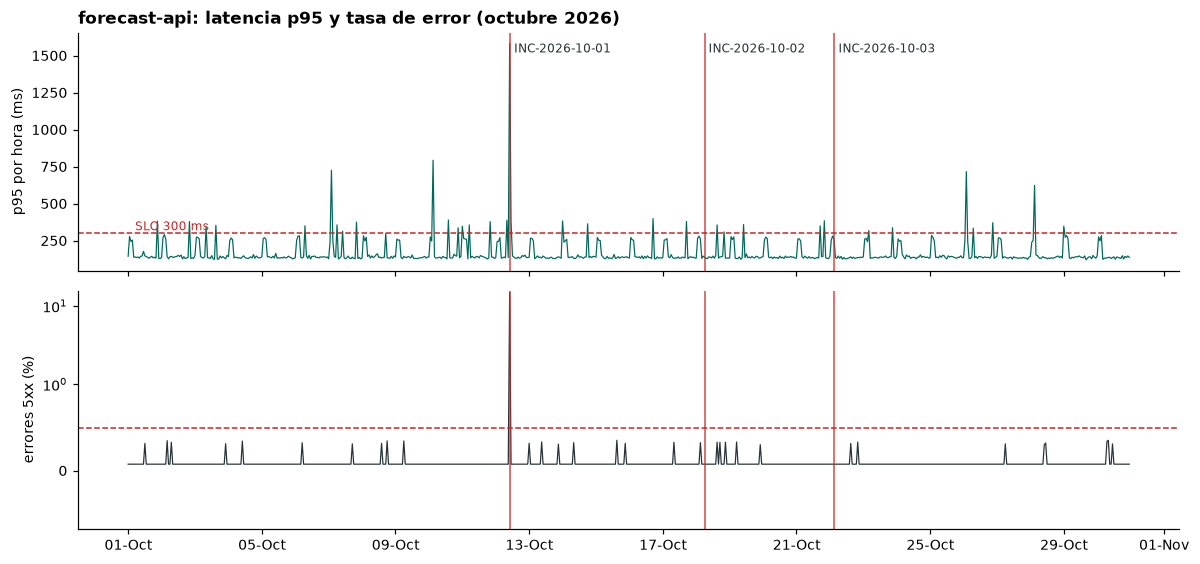

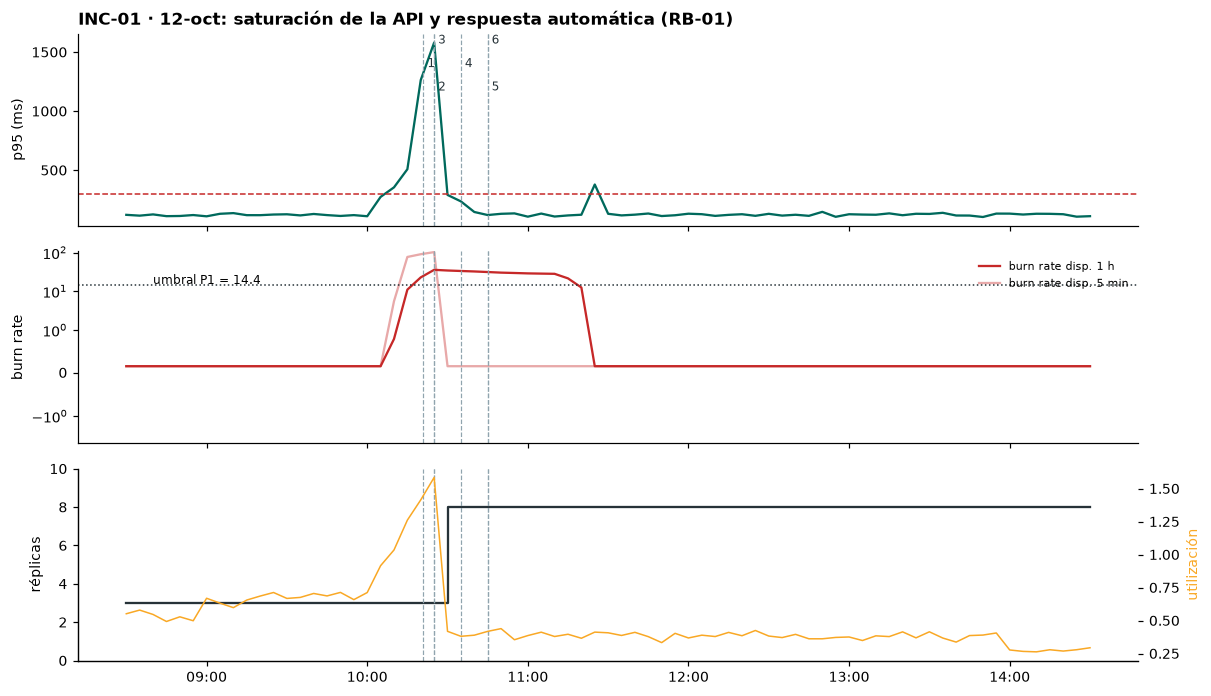

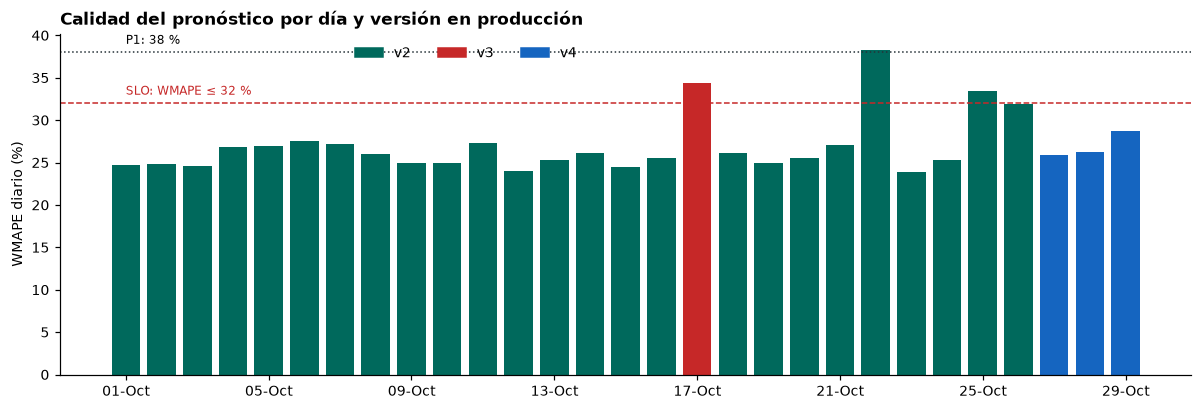

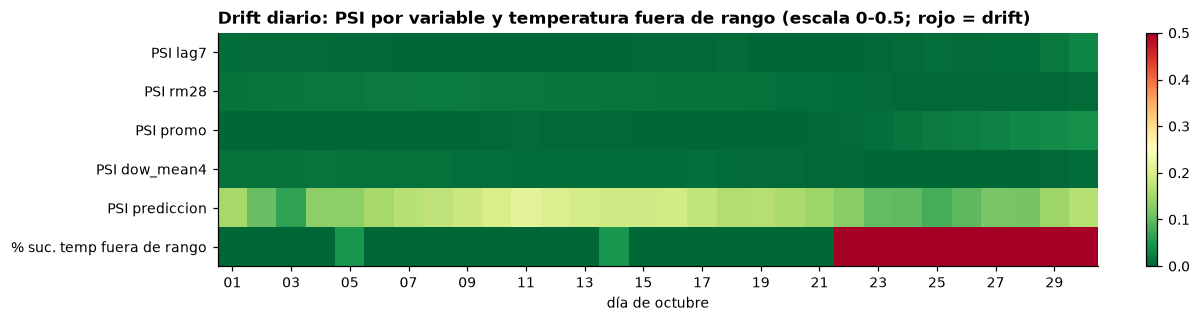

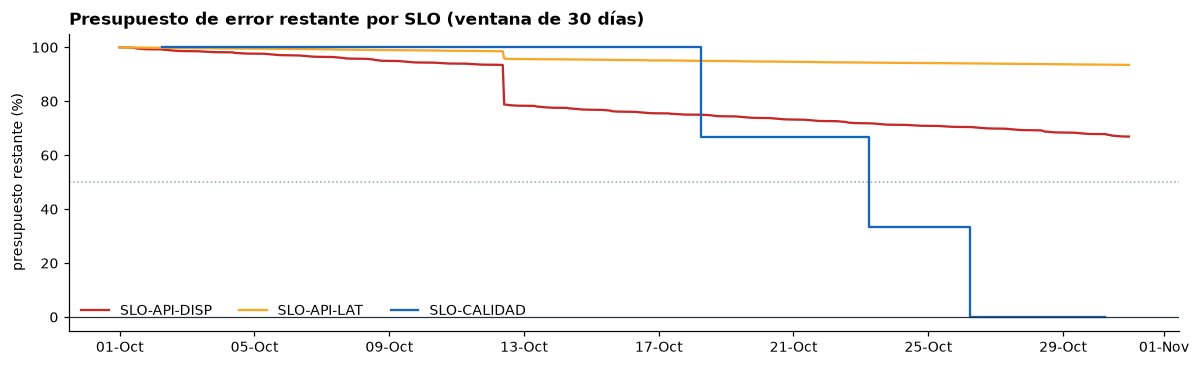

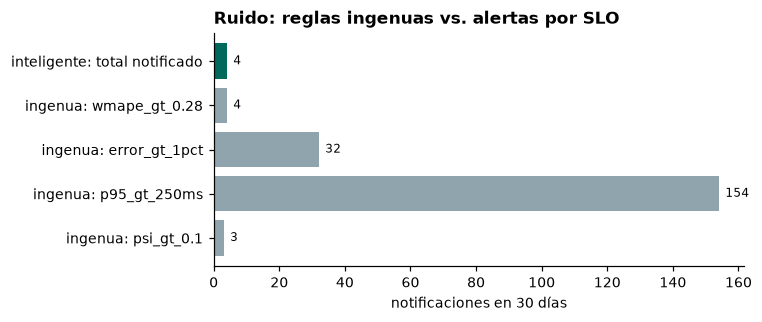

In [ ]:
# =============================================================================
# Celda 12.- Dashboard operativos.
# =============================================================================
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
FIG = BASE / "figs"
C = {"ok": "#2E7D32", "warn": "#F9A825", "bad": "#C62828", "ink": "#263238", "acc": "#00695C", "mut": "#90A4AE"}
api["ts"] = pd.to_datetime(api["ts"]); quality["fecha"] = pd.to_datetime(quality["fecha"])
api_h = api.set_index("ts").resample("1h").agg({"solicitudes": "sum", "errores": "sum", "lentas": "sum", "p95_ms": "max",
                                                 "replicas": "max", "presupuesto_disp": "last", "presupuesto_lat": "last"})
api_h["tasa_error"] = api_h["errores"] / api_h["solicitudes"]
inc_marks = [(i["detectado"], i["id"], i["severidad"]) for i in responder.incidents]

# 1) API: latencia y errores del mes
fig, ax = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
ax[0].plot(api_h.index, api_h["p95_ms"], color=C["acc"], lw=.8); ax[0].axhline(300, color=C["bad"], ls="--", lw=1)
ax[0].set_ylabel("p95 por hora (ms)"); ax[0].set_title("forecast-api: latencia p95 y tasa de error (octubre 2026)", loc="left", fontweight="bold")
ax[0].text(api_h.index[5], 320, "SLO 300 ms", color=C["bad"], fontsize=8)
ax[1].plot(api_h.index, api_h["tasa_error"] * 100, color=C["ink"], lw=.8); ax[1].axhline(0.5, color=C["bad"], ls="--", lw=1)
ax[1].set_ylabel("errores 5xx (%)"); ax[1].set_yscale("symlog", linthresh=1)
for t0, iid, sev in inc_marks:
    for a in ax: a.axvline(t0, color=C["warn"] if sev == "P2" else C["bad"], lw=1.2, alpha=.7)
    ax[0].text(t0, ax[0].get_ylim()[1] * .92, f" {iid}", fontsize=8, color=C["ink"])
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
fig.tight_layout(); fig.savefig(FIG / "api_mes.png", bbox_inches="tight"); plt.show()

# 2) Zoom INC-01
z = api[(api.ts >= "2026-10-12 08:30") & (api.ts <= "2026-10-12 14:30")]
fig, ax = plt.subplots(3, 1, figsize=(11, 6.4), sharex=True)
ax[0].plot(z.ts, z.p95_ms, color=C["acc"]); ax[0].axhline(300, color=C["bad"], ls="--", lw=1); ax[0].set_ylabel("p95 (ms)")
ax[0].set_title("INC-01 · 12-oct: saturación de la API y respuesta automática (RB-01)", loc="left", fontweight="bold")
ax[1].plot(z.ts, z.burn_disp_1h, label="burn rate disp. 1 h", color=C["bad"]); ax[1].plot(z.ts, z.burn_disp_5m, label="burn rate disp. 5 min", color=C["bad"], alpha=.4)
ax[1].axhline(14.4, color=C["ink"], ls=":", lw=1); ax[1].text(z.ts.iloc[2], 15.5, "umbral P1 = 14.4", fontsize=8)
ax[1].set_yscale("symlog", linthresh=1); ax[1].legend(fontsize=7, frameon=False, loc="upper right"); ax[1].set_ylabel("burn rate")
ax[2].step(z.ts, z.replicas, where="post", color=C["ink"]); ax[2].set_ylabel("réplicas"); ax[2].set_ylim(0, 10)
ax2 = ax[2].twinx(); ax2.plot(z.ts, z.utilizacion, color=C["warn"], lw=1); ax2.set_ylabel("utilización", color=C["warn"])
inc1r = next(i for i in responder.incidents if i["runbook"] == "RB-01")
for p in inc1r["pasos"]:
    for a in ax: a.axvline(p["ts"], color=C["mut"], lw=.8, ls="--")
    ax[0].text(p["ts"], ax[0].get_ylim()[1] * (0.95 - 0.12 * (p["paso"] % 3)), f" {p['paso']}", fontsize=8, color=C["ink"])
ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.tight_layout(); fig.savefig(FIG / "inc01_zoom.png", bbox_inches="tight"); plt.show()

# 3) Calidad del modelo
fig, ax = plt.subplots(figsize=(11, 3.8))
colors = {"v2": C["acc"], "v3": C["bad"], "v4": "#1565C0"}
for _, r in quality.iterrows():
    vv = r["version"].split(",")[0] if "," not in r["version"] else "v2"
    ax.bar(r["fecha"], r["wmape"] * 100, color=colors.get(vv, C["mut"]), width=.8)
ax.axhline(32, color=C["bad"], ls="--", lw=1); ax.text(quality.fecha.iloc[0], 33, "SLO: WMAPE ≤ 32 %", fontsize=8, color=C["bad"])
ax.axhline(38, color=C["ink"], ls=":", lw=1); ax.text(quality.fecha.iloc[0], 39, "P1: 38 %", fontsize=8)
ax.set_ylabel("WMAPE diario (%)"); ax.set_title("Calidad del pronóstico por día y versión en producción", loc="left", fontweight="bold")
from matplotlib.patches import Patch
leg_handles = [Patch(color=c, label=v) for v, c in colors.items()]
ax.legend(handles=leg_handles, frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0.25, 1.0))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
fig.tight_layout(); fig.savefig(FIG / "modelo_wmape.png", bbox_inches="tight"); plt.show()

# 4) Mapa de calor de PSI
hm = drift_df.set_index("fecha")[[f"psi_{f}" for f in KEY_FEATURES] + ["psi_prediccion", "fuera_rango_temp"]].T
fig, ax = plt.subplots(figsize=(11, 3.0))
im = ax.imshow(hm.values, aspect="auto", cmap="RdYlGn_r", vmin=0, vmax=0.5)
ax.set_yticks(range(len(hm.index))); ax.set_yticklabels([s.replace("psi_", "PSI ").replace("fuera_rango_temp", "% suc. temp fuera de rango") for s in hm.index])
ax.set_xticks(range(0, len(hm.columns), 2)); ax.set_xticklabels([pd.Timestamp(c).strftime("%d") for c in hm.columns[::2]])
ax.set_xlabel("día de octubre"); ax.set_title("Drift diario: PSI por variable y temperatura fuera de rango (escala 0-0.5; rojo = drift)", loc="left", fontweight="bold")
fig.colorbar(im, ax=ax, fraction=.02); fig.tight_layout(); fig.savefig(FIG / "psi_heatmap.png", bbox_inches="tight"); plt.show()

# 5) Presupuestos de error
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(api_h.index, api_h["presupuesto_disp"] * 100, label="SLO-API-DISP", color=C["bad"])
ax.plot(api_h.index, api_h["presupuesto_lat"] * 100, label="SLO-API-LAT", color=C["warn"])
qb = quality.set_index("fecha")["presupuesto_restante"]
ax.step(qb.index + pd.Timedelta(hours=30), qb * 100, where="post", label="SLO-CALIDAD", color="#1565C0")
ax.axhline(0, color=C["ink"], lw=.8); ax.axhline(50, color=C["mut"], ls=":", lw=1)
ax.set_ylabel("presupuesto restante (%)"); ax.legend(frameon=False, ncol=3)
ax.set_title("Presupuesto de error restante por SLO (ventana de 30 días)", loc="left", fontweight="bold")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
fig.tight_layout(); fig.savefig(FIG / "error_budget.png", bbox_inches="tight"); plt.show()

# 6) Ruido de alertas
fig, ax = plt.subplots(figsize=(7, 3.0))
cats = list(naive.count.keys())
ax.barh([f"ingenua: {c}" for c in cats], [naive.count[c] for c in cats], color=C["mut"])
ax.barh(["inteligente: total notificado"], [len(engine.notifications)], color=C["acc"])
for i, v in enumerate([naive.count[c] for c in cats] + [len(engine.notifications)]): ax.text(v + 2, i, str(v), va="center", fontsize=8)
ax.set_xlabel("notificaciones en 30 días"); ax.set_title("Ruido: reglas ingenuas vs. alertas por SLO", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "ruido_alertas.png", bbox_inches="tight"); plt.show()

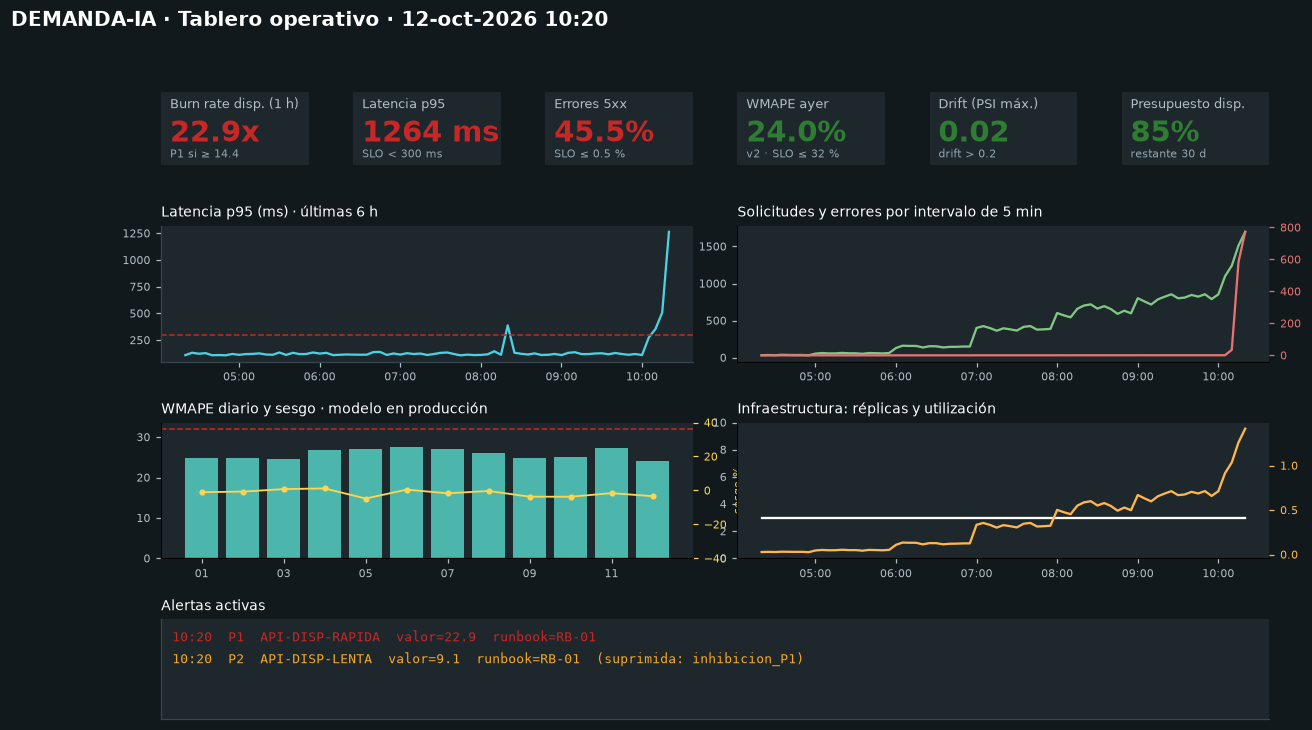

In [ ]:
# =============================================================================
# Celda 13.- Tablero operativo compuesto (instantánea 12-oct 10:20, durante INC-01).
# =============================================================================
def tile(ax, title, value, status, sub=""):
    col = {"ok": C["ok"], "warn": C["warn"], "bad": C["bad"]}[status]
    ax.set_facecolor("#1E272C"); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    ax.text(.06, .78, title, color="#B0BEC5", fontsize=8.5, transform=ax.transAxes)
    ax.text(.06, .32, value, color=col, fontsize=19, fontweight="bold", transform=ax.transAxes)
    ax.text(.06, .1, sub, color="#90A4AE", fontsize=7.5, transform=ax.transAxes)

snap = pd.Timestamp("2026-10-12 10:20")
sa = api[api.ts <= snap].iloc[-1]
qa = quality[quality.fecha <= snap].iloc[-1]
da = drift_df[pd.to_datetime(drift_df.fecha) <= snap].iloc[-1]
fig = plt.figure(figsize=(13, 7.4), facecolor="#12191D")
gs = fig.add_gridspec(4, 6, height_ratios=[.8, 1.5, 1.5, 1.1], hspace=.55, wspace=.3)
fig.suptitle("DEMANDA-IA · Tablero operativo · 12-oct-2026 10:20", color="white", x=.02, ha="left", fontsize=13, fontweight="bold")
tiles = [("Burn rate disp. (1 h)", f"{sa.burn_disp_1h:.1f}x", "bad" if sa.burn_disp_1h >= 14.4 else "ok", "P1 si ≥ 14.4"),
         ("Latencia p95", f"{sa.p95_ms:.0f} ms", "bad" if sa.p95_ms > 300 else "ok", "SLO < 300 ms"),
         ("Errores 5xx", f"{sa.tasa_error:.1%}", "bad" if sa.tasa_error > .005 else "ok", "SLO ≤ 0.5 %"),
         ("WMAPE ayer", f"{qa.wmape:.1%}", "ok" if qa.wmape <= .32 else "bad", f"{qa.version} · SLO ≤ 32 %"),
         ("Drift (PSI máx.)", f"{da.psi_max:.2f}", "ok" if da.psi_max < .1 else ("warn" if da.psi_max < .2 else "bad"), "drift > 0.2"),
         ("Presupuesto disp.", f"{max(sa.presupuesto_disp,0):.0%}", "ok" if sa.presupuesto_disp > .5 else "warn", "restante 30 d")]
for j, tl in enumerate(tiles): tile(fig.add_subplot(gs[0, j]), *tl)
w = api[(api.ts >= snap - pd.Timedelta(hours=6)) & (api.ts <= snap)]
def dark(ax, title):
    ax.set_facecolor("#1E272C"); ax.tick_params(colors="#B0BEC5", labelsize=7)
    for s in ax.spines.values(): s.set_color("#37474F")
    ax.set_title(title, color="white", fontsize=9, loc="left")
a1 = fig.add_subplot(gs[1, :3]); dark(a1, "Latencia p95 (ms) · últimas 6 h")
a1.plot(w.ts, w.p95_ms, color="#4DD0E1"); a1.axhline(300, color=C["bad"], ls="--", lw=1); a1.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
a2 = fig.add_subplot(gs[1, 3:]); dark(a2, "Solicitudes y errores por intervalo de 5 min")
a2.plot(w.ts, w.solicitudes, color="#81C784"); a2b = a2.twinx(); a2b.plot(w.ts, w.errores, color="#E57373"); a2b.tick_params(colors="#E57373", labelsize=7)
a2.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
qq = quality[quality.fecha <= snap]
a3 = fig.add_subplot(gs[2, :3]); dark(a3, "WMAPE diario y sesgo · modelo en producción")
a3.bar(qq.fecha, qq.wmape * 100, color="#4DB6AC"); a3.axhline(32, color=C["bad"], ls="--", lw=1)
a3b = a3.twinx(); a3b.plot(qq.fecha, qq.sesgo * 100, color="#FFD54F", lw=1.2, marker="o", ms=3); a3b.set_ylim(-40, 40)
a3b.tick_params(colors="#FFD54F", labelsize=7); a3b.set_ylabel("sesgo %", color="#FFD54F", fontsize=7)
a3.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
a4 = fig.add_subplot(gs[2, 3:]); dark(a4, "Infraestructura: réplicas y utilización")
a4.step(w.ts, w.replicas, color="white", where="post"); a4.set_ylim(0, 10); a4b = a4.twinx(); a4b.plot(w.ts, w.utilizacion, color="#FFB74D"); a4b.tick_params(colors="#FFB74D", labelsize=7)
a4.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
a5 = fig.add_subplot(gs[3, :]); a5.set_facecolor("#1E272C"); a5.set_xticks([]); a5.set_yticks([])
for s in a5.spines.values(): s.set_color("#37474F")
a5.set_title("Alertas activas", color="white", fontsize=9, loc="left")
act = [e for e in engine.events if e["ts"] <= snap.to_pydatetime() and e["estado"] == "firing" and e["ts"] >= (snap - pd.Timedelta(hours=1)).to_pydatetime()]
for k, e in enumerate(act[:4]):
    col = C["bad"] if e["severidad"] == "P1" else C["warn"]
    sup = f"  (suprimida: {e.get('suprimida_por')})" if e.get("suprimida_por") else ""
    a5.text(.01, .78 - k * .22, f"{e['ts']:%H:%M}  {e['severidad']}  {e['regla']}  valor={e['valor']}  runbook={e['runbook']}{sup}", color=col, fontsize=8.5, family="monospace", transform=a5.transAxes)
fig.savefig(FIG / "dashboard_operativo.png", bbox_inches="tight", facecolor=fig.get_facecolor()); plt.show()

## 12. Exportes: trazas, informes de incidente y registro en MLflow

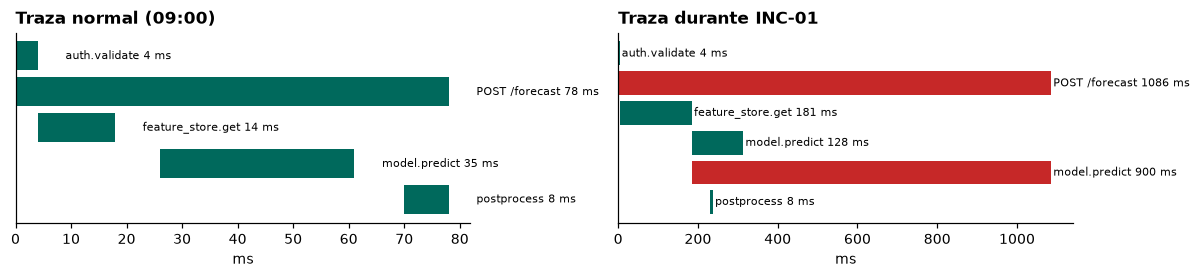

Spans exportados: 4117 | líneas de log: 214


In [ ]:
# =============================================================================
# Celda 14.- Trazas OpenTelemetry a JSON.
# =============================================================================
spans = span_exporter.get_finished_spans()
span_rows = [{"trace_id": format(s.context.trace_id, "032x"), "span_id": format(s.context.span_id, "016x"),
              "parent_id": format(s.parent.span_id, "016x") if s.parent else None, "name": s.name,
              "start": datetime.fromtimestamp(s.start_time / 1e9, tz=timezone.utc).replace(tzinfo=None).isoformat(timespec="milliseconds"),
              "duration_ms": round((s.end_time - s.start_time) / 1e6, 1), "status": s.status.status_code.name,
              "attributes": dict(s.attributes)} for s in spans]
pd.DataFrame(span_rows).to_json(BASE / "traces" / "spans.jsonl", orient="records", lines=True, force_ascii=False)

# ejemplo de cascada: traza normal vs traza durante INC-01
sdf = pd.DataFrame(span_rows); sdf["start"] = pd.to_datetime(sdf["start"])
roots = sdf[(sdf.name == "POST /forecast")]
t_ok = roots[roots.start < "2026-10-12 09:00"].iloc[-1].trace_id
cand = roots[(roots.start >= "2026-10-12 10:00") & (roots.start <= "2026-10-12 11:30")]
t_bad = (cand[cand.status == "ERROR"] if (cand.status == "ERROR").any() else cand).iloc[0].trace_id
fig, axs = plt.subplots(1, 2, figsize=(11, 2.6))
for ax, tid, ttl in [(axs[0], t_ok, "Traza normal (09:00)"), (axs[1], t_bad, "Traza durante INC-01")]:
    s = sdf[sdf.trace_id == tid].sort_values("start"); t0 = s.start.min()
    for k, (_, r) in enumerate(s.iterrows()):
        off = (r.start - t0).total_seconds() * 1000
        ax.barh(k, r.duration_ms, left=off, color=C["bad"] if r.status == "ERROR" else C["acc"])
        ax.text(off + r.duration_ms + 5, k, f"{r['name']} {r.duration_ms:.0f} ms", va="center", fontsize=7)
    ax.invert_yaxis(); ax.set_yticks([]); ax.set_xlabel("ms"); ax.set_title(ttl, loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "trazas_cascada.png", bbox_inches="tight"); plt.show()

# informes de incidente
def fmt(v): return v.isoformat(sep=" ", timespec="minutes") if isinstance(v, (datetime, pd.Timestamp)) else v
for inc in responder.incidents:
    out = {k: fmt(v) for k, v in inc.items() if k != "pasos"}
    out["pasos"] = [{k: fmt(v) for k, v in p.items()} for p in inc["pasos"]]
    (BASE / "incidents" / f"{inc['id']}.json").write_text(json.dumps(out, ensure_ascii=False, indent=2), encoding="utf-8")
api.to_csv(BASE / "reports" / "api_5min.csv", index=False)
quality.to_csv(BASE / "reports" / "calidad_diaria.csv", index=False)
drift_df.to_csv(BASE / "reports" / "drift_diario.csv", index=False)
batch.to_csv(BASE / "reports" / "batch_nocturno.csv", index=False)
pd.DataFrame(engine.events).to_csv(BASE / "reports" / "alertas_eventos.csv", index=False)
pd.DataFrame(engine.notifications).to_csv(BASE / "reports" / "alertas_notificadas.csv", index=False)
print("Spans exportados:", len(span_rows), "| líneas de log:", sum(1 for _ in open(LOG_PATH, encoding="utf-8")))

In [ ]:
# =============================================================================
# Celda 15.- Resultados de Monitoreo.
# =============================================================================
def ms(ts): return int(pd.Timestamp(ts).timestamp() * 1000)

with mlflow.start_run(experiment_id=EXP_MON, run_name="produccion-2026-10") as prod:
    mlflow.set_tags({"servicio": "demanda-ia", "ambiente": "produccion", "periodo": "2026-10-01/2026-10-30",
                     "mlflow.note.content": "Monitoreo continuo de DEMANDA-IA: API, batch nocturno, calidad y drift."})
    metrics = []
    for ts, r in api_h.iterrows():
        step = int((ts - pd.Timestamp(SIM_START)).total_seconds() // 3600)
        for k, v in [("api_p95_ms", r.p95_ms), ("api_tasa_error", r.tasa_error), ("api_solicitudes_h", r.solicitudes),
                     ("api_replicas", r.replicas), ("presupuesto_disp", r.presupuesto_disp), ("presupuesto_lat", r.presupuesto_lat)]:
            metrics.append(Metric(k, float(v), ms(ts), step))
    for _, r in quality.iterrows():
        step = int((r.fecha - pd.Timestamp(SIM_START)).days)
        for k in ["wmape", "sesgo", "presupuesto_restante", "wmape_respiratorio", "sesgo_respiratorio", "cobertura_demanda", "valor_en_riesgo_mxn"]:
            metrics.append(Metric(f"modelo_{k}", float(r[k]), ms(r.fecha), step))
    for _, r in drift_df.iterrows():
        step = int((pd.Timestamp(r.fecha) - pd.Timestamp(SIM_START)).days)
        for k in [c for c in drift_df.columns if c.startswith("psi_") or c in ("pct_features_drift", "fuera_rango_temp", "anomalia_temp_c")]:
            metrics.append(Metric(f"drift_{k}", float(r[k]), ms(r.fecha), step))
    for _, r in batch.iterrows():
        metrics.append(Metric("batch_duracion_min", float(r.duracion_min), ms(r.fecha), int((r.fecha - pd.Timestamp(SIM_START)).days)))
    for i in range(0, len(metrics), 900):
        client.log_batch(prod.info.run_id, metrics=metrics[i:i + 900])
    mlflow.log_metrics({"alertas_notificadas_total": len(engine.notifications), "alertas_ingenuas_total": sum(naive.count.values()),
                        "reduccion_ruido_pct": 100 * (1 - len(engine.notifications) / sum(naive.count.values())),
                        "disponibilidad_30d": summary["Disponibilidad API (30 d)"], "latencia_ok_30d": summary["Solicitudes < 300 ms (30 d)"],
                        "dias_wmape_ok_pct": summary["Días con WMAPE <= 32 %"]})
    mlflow.log_artifacts(str(BASE / "config"), "config")
    mlflow.log_artifacts(str(BASE / "figs"), "dashboards")
    mlflow.log_artifacts(str(BASE / "reports"), "reportes")
    mlflow.log_artifact(str(LOG_PATH), "logs")
    mlflow.log_artifact(str(BASE / "traces" / "spans.jsonl"), "trazas")
    for inc in responder.incidents:
        with mlflow.start_run(experiment_id=EXP_MON, run_name=inc["id"], nested=True):
            mlflow.set_tags({"severidad": inc["severidad"], "runbook": inc["runbook"], "slo": inc["slo"], "regla": inc["regla"],
                             "titulo": inc["titulo"], "estado": inc["estado"]})
            mlflow.log_metrics({"mttd_min": inc["mttd_min"], "mttr_min": inc["mttr_min"], "pasos_runbook": len(inc["pasos"]),
                                "pasos_automaticos": sum(p["tipo"] == "auto" for p in inc["pasos"])})
            mlflow.log_artifact(str(BASE / "incidents" / f"{inc['id']}.json"), "incidente")
print("Run de monitoreo:", prod.info.run_id)
aliases = client.get_registered_model(REG_MODEL).aliases            # alias -> versión
mv = client.search_model_versions(f"name='{REG_MODEL}'")
pd.DataFrame([{"version": v.version, "alias": ", ".join(a for a, ver in aliases.items() if str(ver) == str(v.version)),
               "estado": v.tags.get("estado", ""), "descripcion": v.description} for v in mv]).sort_values("version")

Run de monitoreo: 72d483e853894461984b67ff34aec4b2


,version,alias,estado,descripcion
3,1,,archivado,v1: datos hasta 2026-06-30
2,2,previous,,v2: datos hasta 2026-09-30
1,3,,rechazado-rollback,v3: datos hasta 2026-10-15
0,4,champion,champion,v4: datos hasta 2026-10-24


## 13. (Opcional) Abrir la interfaz de MLflow

**En Colab**, esta celda levanta el servidor de MLflow sobre la base `sqlite` del notebook, espera a que responda y da un enlace para abrirlo en otra pestaña. Agrega las opciones de seguridad de MLflow 3 (`--allowed-hosts`, `--cors-allowed-origins`, `--x-frame-options`) solo si la versión instalada las tiene; sin ellas, el proxy de Colab recibe un error 500. Si el servidor no arranca, la celda imprime las últimas líneas de su log.

**En una computadora local**, la celda solo imprime el comando con la ruta absoluta de la base. Ejecútalo en una terminal (con el entorno del notebook activado) y abre `http://localhost:5000`.

In [ ]:
# =============================================================================
# Celda 16.- Ejecución de los resultados en MLflow, colab o local
# =============================================================================
import subprocess, sys, time, urllib.request

DB_URI = f"sqlite:///{(BASE / 'mlflow.db').as_posix()}"

if "google.colab" in sys.modules:
    LOG = BASE / "mlflow_server.log"
    help_txt = subprocess.run(["mlflow", "server", "--help"], capture_output=True, text=True).stdout
    cmd = ["mlflow", "server", "--backend-store-uri", DB_URI, "--port", "5000", "--host", "0.0.0.0"]
    # Opciones de seguridad de MLflow 3: se agregan solo si la versión instalada las tiene
    for flag, val in [("--allowed-hosts", "*"), ("--cors-allowed-origins", "*"), ("--x-frame-options", "NONE")]:
        if flag in help_txt:
            cmd += [flag, val]
    print(" ".join(cmd))
    subprocess.run(["pkill", "-f", "mlflow server"])          # detiene un servidor previo, si lo hay
    subprocess.Popen(cmd, stdout=open(LOG, "w"), stderr=subprocess.STDOUT)
    for _ in range(60):                                        # espera hasta 2 minutos
        try:
            urllib.request.urlopen("http://127.0.0.1:5000/health", timeout=2)
            print("Servidor de MLflow listo")
            break
        except Exception:
            time.sleep(2)
    else:
        print("El servidor no respondió. Últimas líneas del log:")
        print(LOG.read_text()[-3000:])
    from google.colab import output # pyright: ignore[reportMissingImports]
    output.serve_kernel_port_as_window(5000)                   # enlace para abrir MLflow en otra pestaña
else:
    print("Ejecuta este comando en otra terminal, con el entorno virtual activado:\n")
    print(f"mlflow server --backend-store-uri {DB_URI} --port 5000")
    print("\nDespués abre http://localhost:5000 y cambia a 'Model training'.")

Ejecuta este comando en otra terminal, con el entorno virtual activado:

mlflow server --backend-store-uri sqlite:///C:/Users/JoseGerardoOrtiz/Act8/demanda_ia_obs/mlflow.db --port 5000

Después abre http://localhost:5000 y cambia a 'Model training'.
